# Math Buddy – An Intelligent Tutoring System (ITS) for Elementary Math

**Course:** Machine Learning – Midterm Project

## Group Members

| Name | Last name | Student ID |
|---|---|---|
| _TBD_ | _TBD_ | _TBD_ |

## Overview

*Math Buddy* is a tablet tutor for elementary school math (addition, subtraction, multiplication,
division, fractions). It talks with the student in **text**, sees the student through **visual** input
(handwriting, front camera) and hears the student through **audio** input (spoken answers, voice tone).

Each functionality of the tutor is one block, and every block is a supervised or an unsupervised
learning task:

| Block | Task | Type | Modality |
|---|---|---|---|
| B1 | Interest detection | Supervised (classification) | Text |
| B2 | Struggle topic detection | Supervised (classification) | Text |
| B3 | Handwritten digit recognition | Supervised (classification) | Visual |
| B4 | Attention detection | Supervised (classification) | Visual |
| B5a | Spoken digit recognition | Supervised (classification) | Audio |
| B5b | Confidence detection | Supervised (classification) | Audio |
| B6 | Mastery percentage over time | Supervised (probability) | Combined |
| B7 | Error type discovery | Unsupervised (K-Means) | Combined |
| B8 | Student profiles | Unsupervised (K-Means) | Combined |

Every supervised block follows the same template:
**1. Data → 2. Preprocessing → 3. Train/test split → 4. Model → 5. Evaluation → 6. Example prediction (Can's case)**.

## 0. Setup

Common imports and settings used by all blocks.
`RANDOM_STATE` is fixed so that every run gives the same results (reproducibility).
All plots are also saved as PNG files in the `outputs/` folder so they can be used in the report.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42                 # same random choices on every run
OUTPUT_DIR = "outputs"            # folder for the report figures
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", category=FutureWarning)


def save_figure(fig, filename):
    # Save a matplotlib figure into the outputs folder (used for the report).
    path = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")


print("Setup complete.")

Setup complete.


---
## Block B3 – Handwritten Digit Recognition (Supervised · Visual)

**Role in the tutor:** Can writes his answer with his finger on the tablet. The tutor must read that
handwritten digit and decide whether the answer is correct.

- **Task:** multi-class classification (10 classes: digits 0–9)
- **Dataset:** real data – `sklearn.datasets.load_digits` (1797 handwritten digits, each an 8×8 grayscale image)
- **Input structure:** `pixel_1 … pixel_64` – the 8×8 image flattened row by row into 64 numbers,
  each pixel is an ink intensity between 0 (white) and 16 (black)
- **Label:** `digit` (0–9)
- **Output structure:** predicted `digit` + the model's `probability` for that digit

### B3.1 Data

We load the dataset and put it into a table (DataFrame) with the column names defined in our block design.

In [2]:
from sklearn.datasets import load_digits

digits = load_digits()

pixel_columns = [f"pixel_{i}" for i in range(1, 65)]          # pixel_1 ... pixel_64
b3_df = pd.DataFrame(digits.data, columns=pixel_columns)
b3_df["digit"] = digits.target                               # the label column

print("Dataset shape (rows, columns):", b3_df.shape)
print("\nNumber of examples per digit:")
print(b3_df["digit"].value_counts().sort_index().to_string())
b3_df.head()

Dataset shape (rows, columns): (1797, 65)

Number of examples per digit:
digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,pixel_10,...,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,pixel_64,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


Figure saved: outputs/b3_sample_digits.png


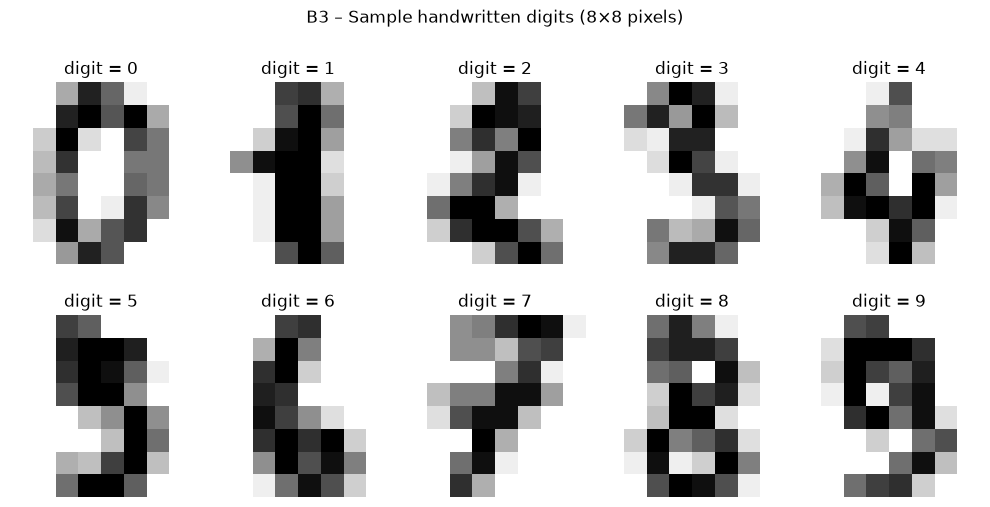

In [3]:
# Show some example images so we can see what the model receives as input
fig, axes = plt.subplots(2, 5, figsize=(10, 5.5))
for ax, digit in zip(axes.ravel(), range(10)):
    first_index = b3_df.index[b3_df["digit"] == digit][0]          # first image of this digit
    image = b3_df.loc[first_index, pixel_columns].to_numpy().reshape(8, 8)
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"digit = {digit}")
    ax.axis("off")
fig.suptitle("B3 – Sample handwritten digits (8×8 pixels)")
plt.tight_layout()
save_figure(fig, "b3_sample_digits.png")
plt.show()

### B3.2 Preprocessing

- **Missing values:** we check them; this dataset has none, so no imputation is needed.
- **Scaling:** pixel values are 0–16. We will standardize them with `StandardScaler`, which helps
  Logistic Regression converge. The scaler is placed **inside a Pipeline** (next steps) so it is
  fitted **only on the training data** – this prevents data leakage.

In [4]:
print("Missing values in the whole table:", b3_df.isna().sum().sum())
print("Pixel value range: min =", b3_df[pixel_columns].min().min(),
      ", max =", b3_df[pixel_columns].max().max())

X_b3 = b3_df[pixel_columns]   # input features (64 pixels)
y_b3 = b3_df["digit"]         # label

Missing values in the whole table: 0
Pixel value range: min = 0.0 , max = 16.0


### B3.3 Train / test split

80% of the images are used for training and 20% are kept aside for testing.
`stratify=y_b3` keeps the same proportion of each digit in both parts.

In [5]:
X_b3_train, X_b3_test, y_b3_train, y_b3_test = train_test_split(
    X_b3, y_b3, test_size=0.2, stratify=y_b3, random_state=RANDOM_STATE)

print("Training set:", X_b3_train.shape, " Test set:", X_b3_test.shape)

Training set: (1437, 64)  Test set: (360, 64)


### B3.4 Model

A `Pipeline` chains the two steps: **StandardScaler → LogisticRegression**.
Calling `fit` on the pipeline fits the scaler and the model on the training data only.
`max_iter=2000` gives the optimizer enough iterations to converge.

In [6]:
b3_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
b3_model.fit(X_b3_train, y_b3_train)
print("B3 model trained.")

B3 model trained.


### B3.5 Evaluation

- **Accuracy:** the share of test images whose digit is predicted correctly.
- **Classification report:** precision, recall and F1-score for each digit.
- **Confusion matrix:** rows are the true digits, columns are the predicted digits;
  numbers outside the diagonal show which digits get confused with each other.

B3 test accuracy: 0.972

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

Figure saved: outputs/b3_confusion_matrix.png


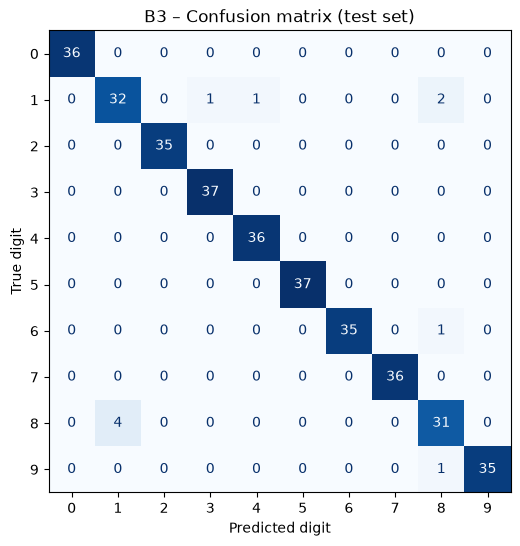

In [7]:
y_b3_pred = b3_model.predict(X_b3_test)

b3_accuracy = accuracy_score(y_b3_test, y_b3_pred)
print(f"B3 test accuracy: {b3_accuracy:.3f}\n")
print(classification_report(y_b3_test, y_b3_pred))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_b3_test, y_b3_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B3 – Confusion matrix (test set)")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
save_figure(fig, "b3_confusion_matrix.png")
plt.show()

### B3.6 Example prediction – Can writes his answer

The tutor asks: *"Your team has 3 players on the bench and 4 more join them. How many players now?"*
Can writes his answer on the screen. We simulate his handwriting with an image from the **test set**
(an image the model has never seen during training) that shows the digit 7.

B3 output: {'digit': 7, 'probability': 0.999}
Answer is CORRECT
Top-3 candidates: {7: 0.999, 3: 0.001, 2: 0.0}


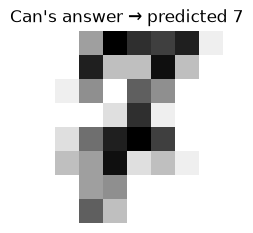

In [8]:
correct_answer = 7

# Can's handwriting: one test image of the digit 7 (never seen during training)
can_index = y_b3_test[y_b3_test == correct_answer].index[0]
can_image = X_b3_test.loc[[can_index]]          # double brackets keep it as a 1-row table

predicted_digit = int(b3_model.predict(can_image)[0])
probabilities = b3_model.predict_proba(can_image)[0]

# Output structure of block B3
b3_output = {"digit": predicted_digit,
             "probability": round(float(probabilities.max()), 3)}
print("B3 output:", b3_output)
print("Answer is", "CORRECT" if predicted_digit == correct_answer else "WRONG")

# Top-3 most likely digits
top3 = np.argsort(probabilities)[::-1][:3]
print("Top-3 candidates:", {int(d): round(float(probabilities[d]), 3) for d in top3})

fig, ax = plt.subplots(figsize=(2.5, 2.5))
ax.imshow(can_image.to_numpy().reshape(8, 8), cmap="gray_r")
ax.set_title(f"Can's answer → predicted {predicted_digit}")
ax.axis("off")
plt.show()

### B3.7 Block function (used by the end-to-end demo)

The whole block is wrapped in one function with a clear input and output.
The demo at the end of the notebook calls the blocks only through such functions, so a block can be
**switched off** (ablation study) and replaced by a fallback, e.g. a spoken answer (B5a) or a keyboard.

In [9]:
def b3_read_handwriting(pixels):
    # Input : 64 pixel values (0-16) of an 8x8 handwritten digit image
    # Output: {"digit": predicted digit, "probability": model confidence}
    x = pd.DataFrame([np.asarray(pixels, dtype=float).ravel()], columns=pixel_columns)
    probabilities = b3_model.predict_proba(x)[0]
    best = int(np.argmax(probabilities))
    return {"digit": int(b3_model.classes_[best]),
            "probability": round(float(probabilities[best]), 3)}


# Quick check with Can's handwriting from B3.6
print("b3_read_handwriting ->", b3_read_handwriting(can_image.to_numpy()))

b3_read_handwriting -> {'digit': 7, 'probability': 0.999}


### B3.8 Limitation found in manual testing – real drawings

The test accuracy (97%) is measured on images that were produced **exactly like the training images**.
`load_digits` images were made by writing a digit on a 32×32 grid, dividing it into 4×4 blocks and counting the
ink in each block, so they are **soft, grey, thick** and fill the box. Real drawings on a tablet look different
(thin, crisp lines, any size). Below we test the B3 model on:
- three digits "drawn" directly on an 8×8 grid (`#` = ink),
- a **real drawing of a 6** made with a mouse (`test_drawings/drawn_six.png`), shrunk to 8×8 in two ways.

thin 1                       true 1 -> predicted 3 (probability 0.999)
small 4                      true 4 -> predicted 8 (probability 1.0)
thin 0                       true 0 -> predicted 4 (probability 0.695)
real 6, plain resize         true 6 -> predicted 4 (probability 0.996)
real 6, load_digits-style    true 6 -> predicted 5 (probability 0.495)


Figure saved: outputs/b3_limitation_drawings.png


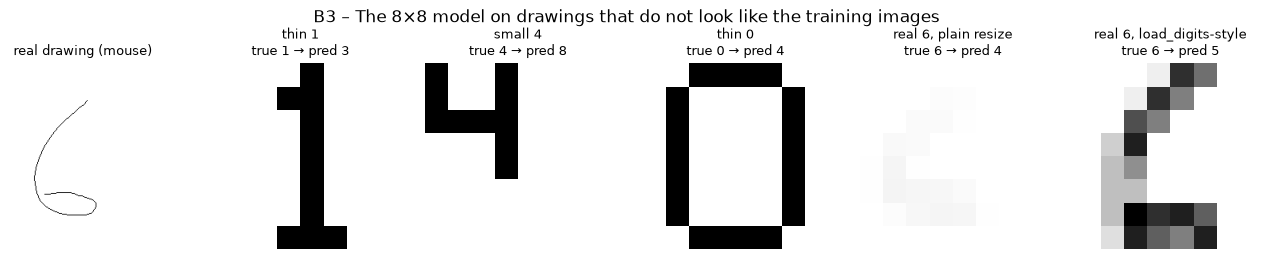

In [10]:
from PIL import Image, ImageFilter
from scipy import ndimage

INK = {".": 0, "+": 8, "#": 16}
ascii_drawings = {
    "thin 1": "....#...\n...##...\n....#...\n....#...\n....#...\n....#...\n....#...\n...###..",
    "small 4": "#..#....\n#..#....\n####....\n...#....\n...#....\n........\n........\n........",
    "thin 0": "..####..\n.#....#.\n.#....#.\n.#....#.\n.#....#.\n.#....#.\n.#....#.\n..####..",
}


def load_ink(path):
    # Read a drawing (dark ink on white paper) and return ink intensity 0-255 (ink = high)
    return 255 - np.array(Image.open(path).convert("L"), dtype=float)


def drawing_to_8x8(ink, stroke=0.08):
    # Prepare a drawing like load_digits: crop -> thicken -> fit in 32x32 -> count ink in 4x4 blocks (0-16)
    mask = (ink > 60).astype(np.uint8) * 255
    ys, xs = np.nonzero(mask)
    crop = Image.fromarray(mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
    k = int(max(crop.size) * stroke) // 2 * 2 + 1                  # thicken BEFORE shrinking
    crop = crop.filter(ImageFilter.MaxFilter(k)) if k > 1 else crop
    w, h = crop.size
    scale = 32 / max(w, h)
    crop = crop.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BILINEAR)
    canvas = Image.new("L", (32, 32), 0)
    canvas.paste(crop, ((32 - crop.size[0]) // 2, (32 - crop.size[1]) // 2))
    bitmap = (np.array(canvas) > 60).astype(int)
    return bitmap.reshape(8, 4, 8, 4).sum(axis=(1, 3)).astype(float)


six_ink = load_ink(os.path.join("test_drawings", "drawn_six.png"))
naive_six = np.array(Image.fromarray(six_ink.astype(np.uint8)).resize((8, 8), Image.BILINEAR)) / 255 * 16

b3_limitation_cases = [(name, 1 if "1" in name else 4 if "4" in name else 0,
                        np.array([[INK[c] for c in row] for row in text.splitlines()], dtype=float))
                       for name, text in ascii_drawings.items()]
b3_limitation_cases += [("real 6, plain resize", 6, naive_six),
                        ("real 6, load_digits-style", 6, drawing_to_8x8(six_ink))]

fig, axes = plt.subplots(1, len(b3_limitation_cases) + 1, figsize=(2.2 * (len(b3_limitation_cases) + 1), 2.6))
axes[0].imshow(six_ink, cmap="gray_r")
axes[0].set_title("real drawing (mouse)", fontsize=9)
axes[0].axis("off")
for ax, (name, true_digit, pixels) in zip(axes[1:], b3_limitation_cases):
    out = b3_read_handwriting(pixels.ravel())
    print(f"{name:28s} true {true_digit} -> predicted {out['digit']} (probability {out['probability']})")
    ax.imshow(pixels, cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"{name}\ntrue {true_digit} → pred {out['digit']}", fontsize=9)
    ax.axis("off")
fig.suptitle("B3 – The 8×8 model on drawings that do not look like the training images")
plt.tight_layout()
save_figure(fig, "b3_limitation_drawings.png")
plt.show()

**Result:** almost all drawings are misread, often with a very high probability. Two reasons:
1. **Distribution shift** – the drawings do not look like the training images (thin, crisp lines instead of soft grey
   blocks), so a high test accuracy does not guarantee good results in real use. A high predicted probability is not a
   guarantee either.
2. **8×8 is too small** – the loop of the drawn 6 is flat; at 8×8 its hole disappears and the 6 looks like a 2 or 5.

**Fix:** train the block on a higher-resolution dataset whose images look more like real pen strokes (next section).

### B3.9 Improved model – MNIST (28×28)

**MNIST** is the standard handwritten digit dataset: 70,000 digits written by about 500 people, each a 28×28 greyscale
image (0 = paper, 255 = ink), with an official split of **60,000 training** and **10,000 test** images.
In MNIST every digit was scaled to fit a 20×20 box and then placed in the 28×28 image so that its
**centre of mass** is in the middle – we prepare our drawings in the same way.

- **Input structure:** 784 pixel values (28 × 28), 0–255
- **Model:** Random Forest with 100 trees (Logistic Regression is slow and weaker on 784 raw pixels; trees do not need scaling).
- The dataset is downloaded once from OpenML (~6 minutes the first time) and cached in `~/scikit_learn_data`.
  We use `parser="liac-arff"` because the default pandas-based reader does not work with the installed pandas version.

Training images: (60000, 784)  Test images: (10000, 784)
Images per digit (training): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Figure saved: outputs/b3_mnist_samples.png


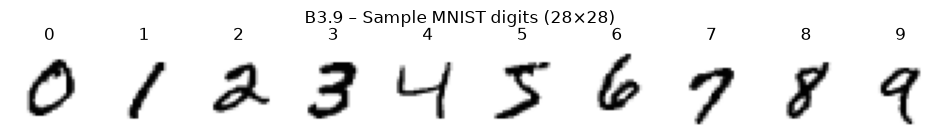

In [11]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff")
X_mnist = mnist.data.astype(np.float32)          # 70,000 x 784
y_mnist = mnist.target.astype(int)

# Official MNIST split: the first 60,000 images are for training, the last 10,000 for testing
X_mnist_train, y_mnist_train = X_mnist[:60000], y_mnist[:60000]
X_mnist_test, y_mnist_test = X_mnist[60000:], y_mnist[60000:]
print("Training images:", X_mnist_train.shape, " Test images:", X_mnist_test.shape)
print("Images per digit (training):", pd.Series(y_mnist_train).value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for digit, ax in enumerate(axes):
    ax.imshow(X_mnist_train[y_mnist_train == digit][0].reshape(28, 28), cmap="gray_r")
    ax.set_title(str(digit))
    ax.axis("off")
fig.suptitle("B3.9 – Sample MNIST digits (28×28)")
save_figure(fig, "b3_mnist_samples.png")
plt.show()

B3 (MNIST) test accuracy: 0.969   (8×8 load_digits model: 0.972)
Figure saved: outputs/b3_mnist_confusion_matrix.png


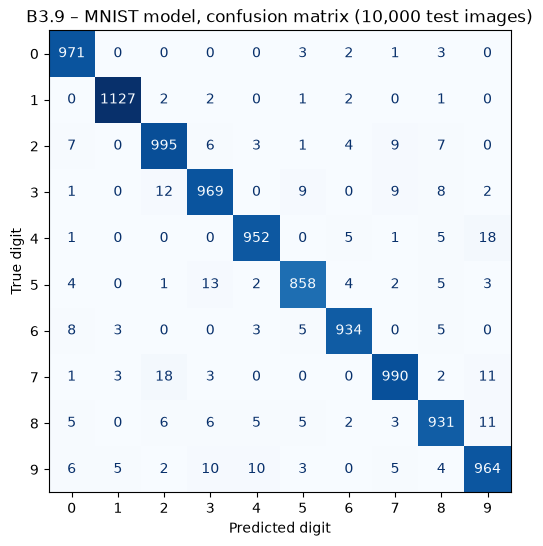

In [12]:
from sklearn.ensemble import RandomForestClassifier

b3_mnist_model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
b3_mnist_model.fit(X_mnist_train, y_mnist_train)

y_mnist_pred = b3_mnist_model.predict(X_mnist_test)
b3_mnist_accuracy = accuracy_score(y_mnist_test, y_mnist_pred)
print(f"B3 (MNIST) test accuracy: {b3_mnist_accuracy:.3f}   (8×8 load_digits model: {b3_accuracy:.3f})")

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_mnist_test, y_mnist_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B3.9 – MNIST model, confusion matrix (10,000 test images)")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
save_figure(fig, "b3_mnist_confusion_matrix.png")
plt.show()

**Preparing a drawing like MNIST:** crop the digit → make the line a bit thicker → shrink it to fit a 20×20 box
(keeping its shape) → place it in a 28×28 image with its centre of mass in the middle.
This function and `b3_read_drawing()` are the B3 block used by the demo and the web app.

8×8 model  : {'digit': 5, 'probability': 0.495}
MNIST model: {'digit': 6, 'probability': 0.75}


Figure saved: outputs/b3_mnist_vs_8x8.png


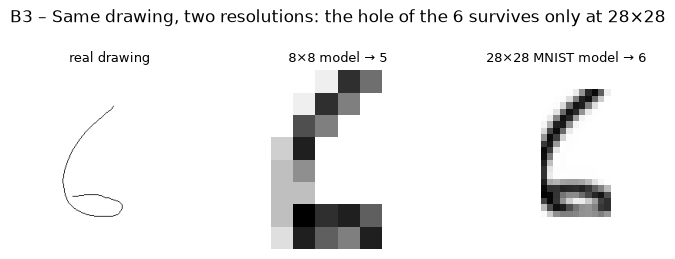

In [13]:
def drawing_to_mnist(ink, stroke=0.08):
    # ink: 2-D array of ink intensity (0 = paper, 255 = ink) of any size -> 28x28 MNIST-style image
    mask = (ink > 60).astype(np.uint8) * 255
    ys, xs = np.nonzero(mask)
    crop = Image.fromarray(mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
    k = int(max(crop.size) * stroke) // 2 * 2 + 1                  # thicken the line (odd filter size)
    crop = crop.filter(ImageFilter.MaxFilter(k)) if k > 1 else crop
    w, h = crop.size
    scale = 20 / max(w, h)                                          # fit in a 20x20 box, keep the shape
    crop = crop.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.LANCZOS)
    canvas = np.zeros((28, 28))
    canvas[:crop.size[1], :crop.size[0]] = np.array(crop, dtype=float)
    cy, cx = ndimage.center_of_mass(canvas)                         # move the centre of mass to the middle
    return np.clip(ndimage.shift(canvas, (14 - cy, 14 - cx), order=1), 0, 255)


def b3_read_drawing(ink):
    # Input : a drawing as a 2-D ink array (any size)
    # Output: {"digit": predicted digit, "probability": model confidence}
    image = drawing_to_mnist(ink)
    probabilities = b3_mnist_model.predict_proba(image.reshape(1, -1))[0]
    best = int(np.argmax(probabilities))
    return {"digit": int(b3_mnist_model.classes_[best]), "probability": round(float(probabilities[best]), 3)}


# The real drawing of a 6 that the 8x8 model could not read
mnist_six = drawing_to_mnist(six_ink)
print("8×8 model  :", b3_read_handwriting(drawing_to_8x8(six_ink).ravel()))
print("MNIST model:", b3_read_drawing(six_ink))

fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
axes[0].imshow(six_ink, cmap="gray_r"); axes[0].set_title("real drawing", fontsize=9)
axes[1].imshow(drawing_to_8x8(six_ink), cmap="gray_r"); axes[1].set_title(
    f"8×8 model → {b3_read_handwriting(drawing_to_8x8(six_ink).ravel())['digit']}", fontsize=9)
axes[2].imshow(mnist_six, cmap="gray_r"); axes[2].set_title(
    f"28×28 MNIST model → {b3_read_drawing(six_ink)['digit']}", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.suptitle("B3 – Same drawing, two resolutions: the hole of the 6 survives only at 28×28")
plt.tight_layout()
save_figure(fig, "b3_mnist_vs_8x8.png")
plt.show()

---
## Block B5a – Spoken Digit Recognition (Supervised · Audio)

**Role in the tutor:** instead of writing, Can can say his answer aloud ("nine!").
The tutor must recognize which digit he said.

- **Task:** multi-class classification (10 classes: digits 0–9)
- **Dataset:** real data – *Free Spoken Digit Dataset (FSDD)*,
  https://github.com/Jakobovski/free-spoken-digit-dataset – 3000 English recordings (8 kHz `.wav`),
  6 speakers × 10 digits × 50 repetitions. The file name holds the label: `9_george_3.wav` → digit 9, speaker george.
- **Input structure:** 40 numbers per recording – the mean and the standard deviation of
  20 MFCC coefficients: `mfcc_mean_1 … mfcc_mean_20`, `mfcc_std_1 … mfcc_std_20`
- **Label:** `digit` (0–9)
- **Output structure:** predicted `digit` + `probability`

**What is an MFCC?** A recording is a long list of air-pressure values. MFCCs (Mel-Frequency Cepstral
Coefficients) summarize the *shape of the sound spectrum* in short time frames (a few milliseconds each),
in a way that is similar to how the human ear hears. Every frame gives 20 numbers. Recordings have different
lengths, so we take the **mean** and **standard deviation** of each coefficient over all frames and get a
fixed-size vector of 40 numbers for every recording.

### B5a.1 Data

We read every `.wav` file, extract its 40 MFCC features and store them in a table
together with the `digit` label and the `speaker` name (the speaker is kept only for analysis, not as a model input).
Feature extraction takes only a few seconds.

In [14]:
import glob
import librosa

FSDD_DIR = os.path.join("free-spoken-digit-dataset", "recordings")
SAMPLE_RATE = 8000      # FSDD recordings are 8 kHz
N_MFCC = 20

mfcc_columns = ([f"mfcc_mean_{i}" for i in range(1, N_MFCC + 1)] +
                [f"mfcc_std_{i}" for i in range(1, N_MFCC + 1)])


def extract_mfcc_features(wav_path):
    # Turn one recording into 40 numbers: mean and std of 20 MFCC coefficients
    signal, sr = librosa.load(wav_path, sr=SAMPLE_RATE)
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=N_MFCC, n_fft=512)   # shape: (20, n_frames)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])


rows = []
for path in sorted(glob.glob(os.path.join(FSDD_DIR, "*.wav"))):
    file_name = os.path.basename(path)                  # e.g. "9_george_3.wav"
    digit, speaker, _ = file_name[:-4].split("_")
    rows.append([*extract_mfcc_features(path), int(digit), speaker, file_name])

b5a_df = pd.DataFrame(rows, columns=mfcc_columns + ["digit", "speaker", "file_name"])

print("Dataset shape (rows, columns):", b5a_df.shape)
print("\nRecordings per digit:", b5a_df["digit"].value_counts().sort_index().to_dict())
print("Recordings per speaker:", b5a_df["speaker"].value_counts().to_dict())
b5a_df.head()

Dataset shape (rows, columns): (3000, 43)

Recordings per digit: {0: 300, 1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300}
Recordings per speaker: {'george': 500, 'jackson': 500, 'lucas': 500, 'nicolas': 500, 'theo': 500, 'yweweler': 500}


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,...,mfcc_std_14,mfcc_std_15,mfcc_std_16,mfcc_std_17,mfcc_std_18,mfcc_std_19,mfcc_std_20,digit,speaker,file_name
0,-332.304016,10.847445,33.272438,15.173686,-45.243378,-36.421120,-44.255020,-31.063648,-39.110420,3.106342,...,3.157392,9.957205,5.354388,5.169566,7.996618,3.924484,5.276778,0,george,0_george_0.wav
1,-417.352936,47.666718,13.310434,-0.294709,-36.826641,-43.932827,-41.199291,-27.137020,-35.337845,-3.491680,...,8.923968,6.880262,6.565503,9.707829,8.744446,11.065453,4.681233,0,george,0_george_1.wav
2,-473.703827,16.758699,2.911048,9.098739,-30.834429,-30.852278,-19.248487,-30.931808,-29.264124,-9.983341,...,8.335006,8.621072,6.412456,9.178862,7.117249,8.082186,5.659632,0,george,0_george_10.wav
3,-423.193909,28.659134,9.746981,3.739535,-33.746944,-31.628971,-28.495695,-30.857140,-32.407467,-8.498025,...,6.049812,6.486536,6.787253,9.259416,6.044415,12.006568,5.961236,0,george,0_george_11.wav
4,-407.317047,29.210526,7.041830,9.522633,-43.336502,-34.762310,-31.847549,-31.005375,-40.503773,-7.556608,...,9.775927,5.831202,13.789354,5.574051,7.707474,9.705777,5.266350,0,george,0_george_12.wav


Figure saved: outputs/b5a_waveform_mfcc.png


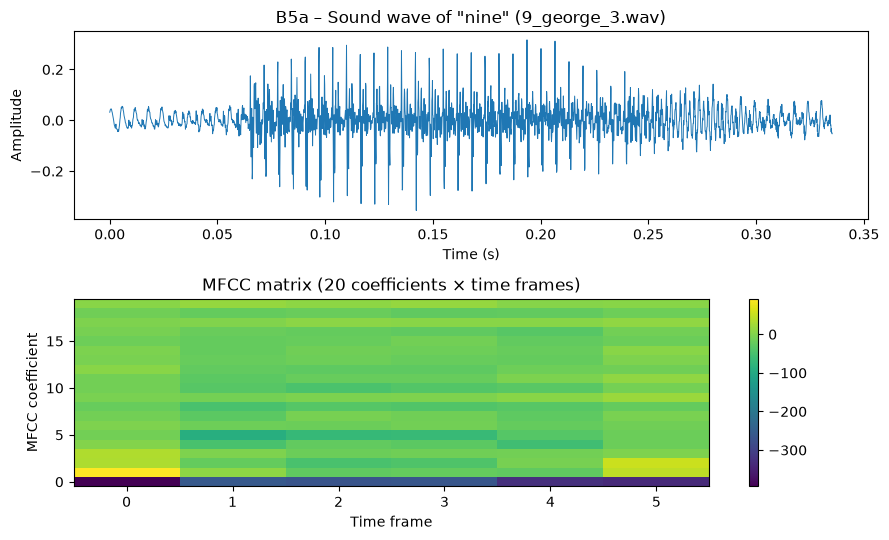

In [15]:
# Visualize one recording: the raw sound wave and its MFCC matrix
example_path = os.path.join(FSDD_DIR, "9_george_3.wav")
signal, sr = librosa.load(example_path, sr=SAMPLE_RATE)
mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=N_MFCC, n_fft=512)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5))
axes[0].plot(np.arange(len(signal)) / sr, signal, linewidth=0.7)
axes[0].set_title('B5a – Sound wave of "nine" (9_george_3.wav)')
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
image = axes[1].imshow(mfcc, aspect="auto", origin="lower", cmap="viridis")
axes[1].set_title("MFCC matrix (20 coefficients × time frames)")
axes[1].set_xlabel("Time frame")
axes[1].set_ylabel("MFCC coefficient")
fig.colorbar(image, ax=axes[1])
plt.tight_layout()
save_figure(fig, "b5a_waveform_mfcc.png")
plt.show()

### B5a.2 Preprocessing

- **Missing values:** checked (none expected, every file produces 40 numbers).
- **Scaling:** MFCC values have very different ranges (the first coefficient is in the hundreds,
  the others are much smaller), so `StandardScaler` is needed. It is again placed inside a Pipeline,
  so it is fitted on the training data only.

In [16]:
print("Missing values in the whole table:", b5a_df[mfcc_columns].isna().sum().sum())
print("\nValue ranges of a few features (very different scales -> scaling is needed):")
print(b5a_df[["mfcc_mean_1", "mfcc_mean_2", "mfcc_std_1", "mfcc_std_20"]].describe().loc[["min", "max"]].round(1))

X_b5a = b5a_df[mfcc_columns]   # 40 input features
y_b5a = b5a_df["digit"]        # label

Missing values in the whole table: 0

Value ranges of a few features (very different scales -> scaling is needed):
     mfcc_mean_1  mfcc_mean_2  mfcc_std_1  mfcc_std_20
min       -695.2        -38.4         6.5          0.6
max       -243.5        188.0       236.2         28.4


### B5a.3 Train / test split

80% training, 20% test, stratified by digit.

In [17]:
X_b5a_train, X_b5a_test, y_b5a_train, y_b5a_test = train_test_split(
    X_b5a, y_b5a, test_size=0.2, stratify=y_b5a, random_state=RANDOM_STATE)

print("Training set:", X_b5a_train.shape, " Test set:", X_b5a_test.shape)

Training set: (2400, 40)  Test set: (600, 40)


### B5a.4 Model

Same structure as B3: **StandardScaler → LogisticRegression** in a Pipeline.

In [18]:
b5a_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])
b5a_model.fit(X_b5a_train, y_b5a_train)
print("B5a model trained.")

B5a model trained.


### B5a.5 Evaluation

Accuracy, per-digit report and confusion matrix on the test set.

B5a test accuracy: 0.915

              precision    recall  f1-score   support

           0       0.86      0.90      0.88        60
           1       0.90      0.92      0.91        60
           2       0.89      0.97      0.93        60
           3       0.88      0.85      0.86        60
           4       1.00      1.00      1.00        60
           5       0.95      0.93      0.94        60
           6       0.85      0.85      0.85        60
           7       0.98      0.90      0.94        60
           8       0.96      0.90      0.93        60
           9       0.89      0.93      0.91        60

    accuracy                           0.92       600
   macro avg       0.92      0.92      0.92       600
weighted avg       0.92      0.92      0.92       600

Figure saved: outputs/b5a_confusion_matrix.png


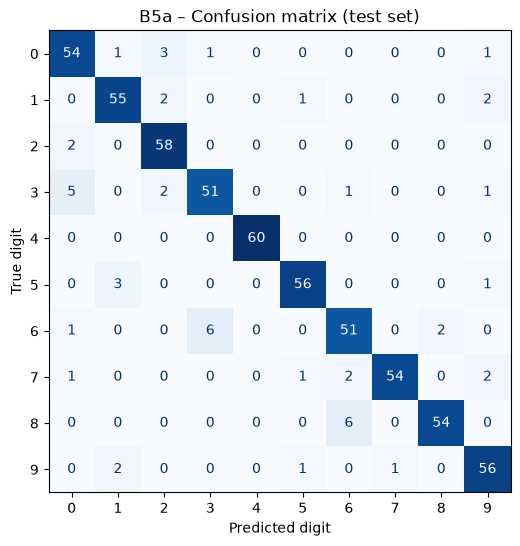

In [19]:
y_b5a_pred = b5a_model.predict(X_b5a_test)

b5a_accuracy = accuracy_score(y_b5a_test, y_b5a_pred)
print(f"B5a test accuracy: {b5a_accuracy:.3f}\n")
print(classification_report(y_b5a_test, y_b5a_pred))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_b5a_test, y_b5a_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B5a – Confusion matrix (test set)")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
save_figure(fig, "b5a_confusion_matrix.png")
plt.show()

### B5a.6 Example prediction – Can says his answer aloud

The tutor asks: *"Your team scored 4 goals in the first half and 5 in the second half. How many goals in total?"*
Can says **"nine!"**. We simulate his voice with a recording of "nine" from the **test set**.

In [20]:
correct_answer = 9

can_audio_index = y_b5a_test[y_b5a_test == correct_answer].index[0]
can_audio_file = b5a_df.loc[can_audio_index, "file_name"]
print("Can's recording:", can_audio_file)

can_audio = X_b5a_test.loc[[can_audio_index]]
probabilities = b5a_model.predict_proba(can_audio)[0]
predicted_digit = int(b5a_model.classes_[probabilities.argmax()])

b5a_output = {"digit": predicted_digit, "probability": round(float(probabilities.max()), 3)}
print("B5a output:", b5a_output)
print("Answer is", "CORRECT" if predicted_digit == correct_answer else "WRONG")

Can's recording: 9_jackson_44.wav
B5a output: {'digit': 9, 'probability': 0.944}
Answer is CORRECT


### B5a.7 Block function (used by the end-to-end demo)

Takes a `.wav` file path, returns the recognized digit and its probability.

In [21]:
def b5a_recognize_speech(wav_path):
    # Input : path of a .wav recording of a spoken digit
    # Output: {"digit": predicted digit, "probability": model confidence}
    x = pd.DataFrame([extract_mfcc_features(wav_path)], columns=mfcc_columns)
    probabilities = b5a_model.predict_proba(x)[0]
    best = int(np.argmax(probabilities))
    return {"digit": int(b5a_model.classes_[best]),
            "probability": round(float(probabilities[best]), 3)}


print("b5a_recognize_speech ->", b5a_recognize_speech(os.path.join(FSDD_DIR, can_audio_file)))

b5a_recognize_speech -> {'digit': 9, 'probability': 0.944}


### B5a.8 Speaker-independent evaluation (a limitation)

The 91.5% accuracy above is **optimistic**: the random split puts recordings of the *same 6 speakers*
into both the training and the test set, so the model has already heard every test voice.
In the real tutor, Can's voice is **new** to the model.

To measure this we use **Leave-One-Speaker-Out** evaluation (`LeaveOneGroupOut`):
the model is trained on 5 speakers and tested on the 6th, unseen speaker; this is repeated for every speaker.

In [22]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.base import clone

speaker_scores = cross_val_score(
    clone(b5a_model), X_b5a, y_b5a,
    groups=b5a_df["speaker"], cv=LeaveOneGroupOut(), scoring="accuracy")

speakers = sorted(b5a_df["speaker"].unique())     # LeaveOneGroupOut uses the groups in sorted order
b5a_speaker_results = pd.DataFrame({"unseen_speaker": speakers,
                                    "accuracy": speaker_scores.round(3)})
print(b5a_speaker_results.to_string(index=False))
print(f"\nAverage accuracy on an unseen speaker: {speaker_scores.mean():.3f}"
      f"  (random split: {b5a_accuracy:.3f})")

unseen_speaker  accuracy
        george     0.252
       jackson     0.550
         lucas     0.434
       nicolas     0.320
          theo     0.702
      yweweler     0.718

Average accuracy on an unseen speaker: 0.496  (random split: 0.915)


### B5a.9 Personalization – a short voice calibration for a new student

**Idea:** on the first day, Math Buddy plays a small game with Can: *"Say each number after me!"*.
These few recordings of Can's own voice are **added to the training data** and the model is retrained.

**Simulation:** for every speaker in turn we treat them as the new student ("Can"):
- training data = all recordings of the other 5 speakers **+ k recordings per digit from the new speaker** (the calibration),
- test data = the **remaining** recordings of the new speaker (calibration recordings are never tested, to avoid leakage).

We try k = 0 (no calibration), 1, 2, 3, 5, 10 and average the accuracy over the 6 speakers.

In [23]:
CALIBRATION_SIZES = [0, 1, 2, 3, 5, 10]     # recordings per digit given by the new student
rng = np.random.RandomState(RANDOM_STATE)

personalization_rows = []
for new_speaker in speakers:
    others = b5a_df[b5a_df["speaker"] != new_speaker]
    new_student = b5a_df[b5a_df["speaker"] == new_speaker]

    # Shuffle the new speaker's recordings once, then take the first k of each digit as calibration
    shuffled = new_student.sample(frac=1, random_state=rng)
    position_within_digit = shuffled.groupby("digit").cumcount()      # 0, 1, 2, ... inside each digit

    for k in CALIBRATION_SIZES:
        calibration = shuffled[position_within_digit < k]
        test_part = shuffled[position_within_digit >= k]

        train_part = pd.concat([others, calibration])
        model = clone(b5a_model).fit(train_part[mfcc_columns], train_part["digit"])
        accuracy = accuracy_score(test_part["digit"], model.predict(test_part[mfcc_columns]))
        personalization_rows.append({"new_speaker": new_speaker,
                                     "calibration_per_digit": k,
                                     "accuracy": accuracy})

b5a_personalization = pd.DataFrame(personalization_rows)

# Table: one row per speaker, one column per calibration size
summary_table = b5a_personalization.pivot(index="new_speaker",
                                          columns="calibration_per_digit",
                                          values="accuracy").round(3)
summary_table.loc["AVERAGE"] = summary_table.mean().round(3)
print("Accuracy on the new speaker (columns = calibration recordings per digit):")
print(summary_table.to_string())

Accuracy on the new speaker (columns = calibration recordings per digit):
calibration_per_digit     0      1      2      3      5      10
new_speaker                                                    
george                 0.252  0.512  0.633  0.683  0.751  0.818
jackson                0.550  0.633  0.656  0.717  0.784  0.835
lucas                  0.434  0.594  0.654  0.704  0.738  0.835
nicolas                0.320  0.424  0.471  0.502  0.616  0.712
theo                   0.702  0.722  0.733  0.772  0.809  0.860
yweweler               0.718  0.786  0.800  0.815  0.833  0.865
AVERAGE                0.496  0.612  0.658  0.699  0.755  0.821


Figure saved: outputs/b5a_personalization.png


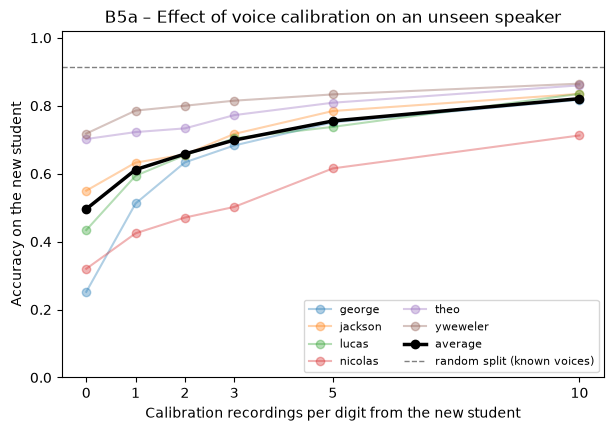

Without calibration: 0.496  |  with 3 recordings per digit (30 in total, ~1 minute): 0.699  |  with 10 per digit: 0.821


In [24]:
average_curve = b5a_personalization.groupby("calibration_per_digit")["accuracy"].mean()

fig, ax = plt.subplots(figsize=(7, 4.5))
for new_speaker, part in b5a_personalization.groupby("new_speaker"):
    ax.plot(part["calibration_per_digit"], part["accuracy"], marker="o", alpha=0.35, label=new_speaker)
ax.plot(average_curve.index, average_curve.values, marker="o", color="black", linewidth=2.5, label="average")
ax.axhline(b5a_accuracy, color="gray", linestyle="--", linewidth=1, label="random split (known voices)")
ax.set_title("B5a – Effect of voice calibration on an unseen speaker")
ax.set_xlabel("Calibration recordings per digit from the new student")
ax.set_ylabel("Accuracy on the new student")
ax.set_xticks(CALIBRATION_SIZES)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, ncol=2, loc="lower right")
save_figure(fig, "b5a_personalization.png")
plt.show()

print(f"Without calibration: {average_curve[0]:.3f}  |  with 3 recordings per digit (30 in total, ~1 minute): "
      f"{average_curve[3]:.3f}  |  with 10 per digit: {average_curve[10]:.3f}")

---
## Block B4 – Attention Detection (Supervised · Visual)

**Role in the tutor:** the tablet's front camera watches Can while he solves problems. Every few seconds
the tutor decides whether he is **attentive**, **distracted** or **tired** and reacts:
attentive → continue, distracted → short attention-grabbing message, tired → suggest a break.
The detected state is also an input of B6 (a mistake made while distracted says less about real knowledge).

- **Task:** multi-class classification (3 classes)
- **Dataset:** **synthetic**. In a real system the three features would be computed from the camera stream
  with a face-landmark tool such as **MediaPipe Face Mesh** or **OpenFace**; public datasets for this task are
  e.g. DAiSEE and EngageNet (videos of students labelled with engagement levels).
- **Input structure** (measured over a short time window, e.g. 10 seconds):

| Column | Meaning | Unit / range |
|---|---|---|
| `screen_gaze_ratio` | share of the time the eyes look at the screen | 0 – 1 |
| `head_angle` | how far the head is turned / tilted away from the screen | degrees, 0 – 60 |
| `blink_rate` | number of blinks | per minute |

- **Label:** `state` ∈ {`attentive`, `distracted`, `tired`}
- **Output structure:** predicted `state` + probability of each state

### B4.1 Data (synthetic)

Every state has a typical "signature" (the numbers are our assumptions, not measured values):

| State | screen_gaze_ratio | head_angle | blink_rate |
|---|---|---|---|
| attentive | high (~0.85) | small (~6°) | normal (~15/min) |
| distracted | low (~0.45) | large (~25°) – looking away | normal (~17/min) |
| tired | medium (~0.65) | medium (~15°) – head drooping | **high** (~26/min) |

Values are drawn from normal distributions around these means with wide spreads, so the classes **overlap**
(as in reality: some attentive children also tilt their head). To imitate a real camera, about 3% of the
values are set to missing (NaN) – the moments when the camera loses the child's face.

In [25]:
ATTENTION_FEATURES = ["screen_gaze_ratio", "head_angle", "blink_rate"]

# Assumed signature of each state: (mean, standard deviation) of every feature
ATTENTION_PROFILES = {
    "attentive":  {"screen_gaze_ratio": (0.85, 0.08), "head_angle": (6, 5),  "blink_rate": (15, 4)},
    "distracted": {"screen_gaze_ratio": (0.45, 0.15), "head_angle": (25, 9), "blink_rate": (17, 5)},
    "tired":      {"screen_gaze_ratio": (0.65, 0.12), "head_angle": (15, 7), "blink_rate": (26, 6)},
}


def generate_attention_data(n_per_state, rng, missing_rate=0.03):
    # Create a synthetic table: n_per_state rows for every attention state
    parts = []
    for state, profile in ATTENTION_PROFILES.items():
        part = pd.DataFrame({feature: rng.normal(mean, std, n_per_state)
                             for feature, (mean, std) in profile.items()})
        part["state"] = state
        parts.append(part)
    data = pd.concat(parts, ignore_index=True)

    # Keep values in physically possible ranges
    data["screen_gaze_ratio"] = data["screen_gaze_ratio"].clip(0, 1)
    data["head_angle"] = data["head_angle"].abs().clip(0, 60)
    data["blink_rate"] = data["blink_rate"].clip(2, 50)

    # The camera sometimes loses the face -> some measurements are missing
    mask = rng.random((len(data), len(ATTENTION_FEATURES))) < missing_rate
    data[ATTENTION_FEATURES] = data[ATTENTION_FEATURES].mask(mask)

    return data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)   # shuffle rows


b4_rng = np.random.default_rng(RANDOM_STATE)
b4_df = generate_attention_data(n_per_state=500, rng=b4_rng)

print("Dataset shape (rows, columns):", b4_df.shape)
print("\nRows per state:", b4_df["state"].value_counts().to_dict())
print("\nAverage of every feature per state:")
print(b4_df.groupby("state")[ATTENTION_FEATURES].mean().round(2))
b4_df.head()

Dataset shape (rows, columns): (1500, 4)

Rows per state: {'tired': 500, 'attentive': 500, 'distracted': 500}

Average of every feature per state:
            screen_gaze_ratio  head_angle  blink_rate
state                                                
attentive                0.85        6.48       15.02
distracted               0.43       25.08       17.31
tired                    0.65       14.97       26.08


,screen_gaze_ratio,head_angle,blink_rate,state
0,0.569990,23.341155,32.761659,tired
1,0.686372,17.205301,25.176640,tired
2,0.802448,6.596129,16.562122,attentive
3,0.909955,2.889161,20.043749,attentive
4,0.877902,8.258843,NaN,attentive


Figure saved: outputs/b4_data_scatter.png


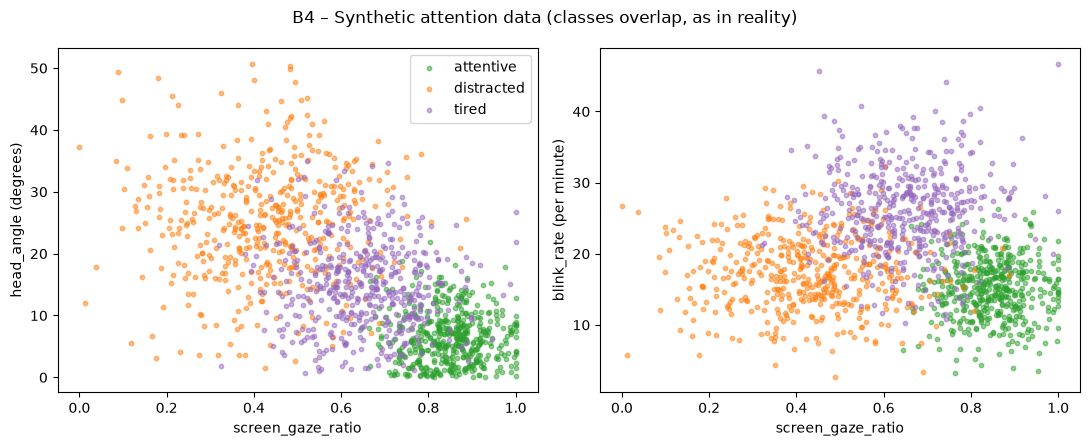

In [26]:
# Look at the data: each dot is one 10-second window, colored by the true state
colors = {"attentive": "tab:green", "distracted": "tab:orange", "tired": "tab:purple"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for state, part in b4_df.groupby("state"):
    axes[0].scatter(part["screen_gaze_ratio"], part["head_angle"], s=10, alpha=0.5, c=colors[state], label=state)
    axes[1].scatter(part["screen_gaze_ratio"], part["blink_rate"], s=10, alpha=0.5, c=colors[state], label=state)
axes[0].set_xlabel("screen_gaze_ratio")
axes[0].set_ylabel("head_angle (degrees)")
axes[1].set_xlabel("screen_gaze_ratio")
axes[1].set_ylabel("blink_rate (per minute)")
axes[0].legend()
fig.suptitle("B4 – Synthetic attention data (classes overlap, as in reality)")
plt.tight_layout()
save_figure(fig, "b4_data_scatter.png")
plt.show()

### B4.2 Preprocessing

- **Missing values:** filled with the **median** of the column by `SimpleImputer`. The median is learned
  from the training data only (the imputer is inside the Pipeline).
- **No scaling:** a Random Forest asks threshold questions such as *"is screen_gaze_ratio < 0.6?"*;
  the answer does not change if a feature is rescaled, so `StandardScaler` is not needed.

In [27]:
print("Missing values per column:")
print(b4_df[ATTENTION_FEATURES].isna().sum().to_string())

X_b4 = b4_df[ATTENTION_FEATURES]
y_b4 = b4_df["state"]

Missing values per column:
screen_gaze_ratio    50
head_angle           41
blink_rate           45


### B4.3 Train / test split

80% training, 20% test, stratified by state.

In [28]:
X_b4_train, X_b4_test, y_b4_train, y_b4_test = train_test_split(
    X_b4, y_b4, test_size=0.2, stratify=y_b4, random_state=RANDOM_STATE)

print("Training set:", X_b4_train.shape, " Test set:", X_b4_test.shape)

Training set: (1200, 3)  Test set: (300, 3)


### B4.4 Model – Random Forest

A **decision tree** classifies a row by asking a sequence of yes/no questions
(*"screen_gaze_ratio < 0.6?" → "head_angle > 20?" → distracted*). It learns the questions itself by choosing,
at every step, the question that separates the classes best. A single deep tree tends to **memorize** the
training data (overfitting).

A **Random Forest** trains many trees and lets them **vote**:
- every tree is trained on a different random sample of the rows (bootstrap sampling),
- at every question a tree may only look at a random subset of the features,

so the trees make *different* mistakes, which cancel out in the vote. The share of votes is the predicted probability.

Settings:
- `n_estimators=200` – number of trees in the forest
- `max_depth=6` – a tree may ask at most 6 questions in a row (limits memorization)

In [29]:
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

b4_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE)),
])
b4_model.fit(X_b4_train, y_b4_train)
print("B4 model trained.")

B4 model trained.


### B4.5 Evaluation

- **Overfitting check:** we compare the accuracy on the training data with the accuracy on the unseen test data.
  If they are close, the model has learned general rules instead of memorizing.
- Classification report and confusion matrix on the test set.
- **Feature importance:** how much each feature helped the trees separate the classes.

Training accuracy: 0.946
Test accuracy:     0.897
Gap:               0.049  (small gap -> no strong overfitting)

              precision    recall  f1-score   support

   attentive       0.94      0.97      0.96       100
  distracted       0.90      0.86      0.88       100
       tired       0.85      0.86      0.86       100

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



Figure saved: outputs/b4_confusion_matrix.png


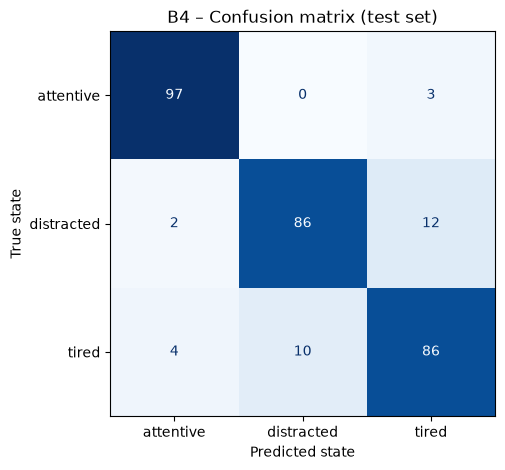

In [30]:
b4_train_accuracy = accuracy_score(y_b4_train, b4_model.predict(X_b4_train))
y_b4_pred = b4_model.predict(X_b4_test)
b4_accuracy = accuracy_score(y_b4_test, y_b4_pred)

print(f"Training accuracy: {b4_train_accuracy:.3f}")
print(f"Test accuracy:     {b4_accuracy:.3f}")
print(f"Gap:               {b4_train_accuracy - b4_accuracy:.3f}  (small gap -> no strong overfitting)\n")
print(classification_report(y_b4_test, y_b4_pred))

state_order = ["attentive", "distracted", "tired"]
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_b4_test, y_b4_pred, labels=state_order),
                       display_labels=state_order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B4 – Confusion matrix (test set)")
ax.set_xlabel("Predicted state")
ax.set_ylabel("True state")
save_figure(fig, "b4_confusion_matrix.png")
plt.show()

Feature importance:
screen_gaze_ratio    0.418
blink_rate           0.299
head_angle           0.283
Figure saved: outputs/b4_feature_importance.png


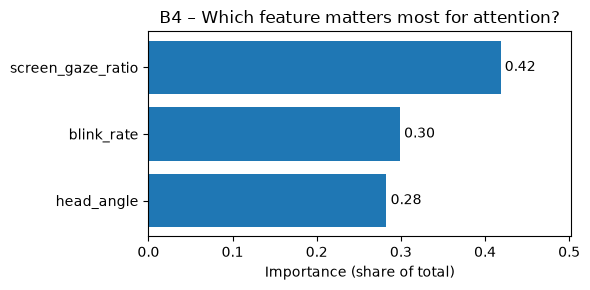

In [31]:
importances = pd.Series(b4_model.named_steps["classifier"].feature_importances_,
                        index=ATTENTION_FEATURES).sort_values()
print("Feature importance:")
print(importances.sort_values(ascending=False).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(importances.index, importances.values, color="tab:blue")
ax.set_xlabel("Importance (share of total)")
ax.set_title("B4 – Which feature matters most for attention?")
for i, value in enumerate(importances.values):
    ax.text(value + 0.005, i, f"{value:.2f}", va="center")
ax.set_xlim(0, importances.max() * 1.2)
plt.tight_layout()
save_figure(fig, "b4_feature_importance.png")
plt.show()

### B4.6 Example prediction – Can looks out of the window

During a football word problem Can hears his friends playing outside and looks out of the window.
In the last 10 seconds the camera measured: he looked at the screen only 42% of the time,
his head was turned 28° away, and he blinked 17 times per minute.

In [32]:
can_measurement = pd.DataFrame([{"screen_gaze_ratio": 0.42, "head_angle": 28, "blink_rate": 17}])

predicted_state = b4_model.predict(can_measurement)[0]
probabilities = b4_model.predict_proba(can_measurement)[0]

b4_output = {"state": predicted_state,
             "probabilities": {s: round(float(p), 3) for s, p in zip(b4_model.classes_, probabilities)}}
print("B4 output:", b4_output)

TUTOR_REACTION = {"attentive": "Continue the lesson.",
                  "distracted": "Show a short attention message: 'Hey Can, the ball is here! ⚽'",
                  "tired": "Suggest a 5-minute break."}
print("Tutor reaction:", TUTOR_REACTION[predicted_state])

B4 output: {'state': 'distracted', 'probabilities': {'attentive': 0.002, 'distracted': 0.988, 'tired': 0.011}}
Tutor reaction: Show a short attention message: 'Hey Can, the ball is here! ⚽'


### B4.7 Block function (used by the end-to-end demo)

In [33]:
def b4_detect_attention(screen_gaze_ratio, head_angle, blink_rate):
    # Input : the three camera features of one time window (a value may be None/NaN if the face was lost)
    # Output: {"state": predicted state, "probabilities": {state: probability}}
    x = pd.DataFrame([{"screen_gaze_ratio": screen_gaze_ratio,
                       "head_angle": head_angle,
                       "blink_rate": blink_rate}], dtype=float)
    probabilities = b4_model.predict_proba(x)[0]
    best = int(np.argmax(probabilities))
    return {"state": b4_model.classes_[best],
            "probabilities": {s: round(float(p), 3) for s, p in zip(b4_model.classes_, probabilities)}}


print("Can looking out of the window ->", b4_detect_attention(0.42, 28, 17))
print("Can focused on the problem    ->", b4_detect_attention(0.90, 4, 14))
print("Can sleepy after school       ->", b4_detect_attention(0.66, 14, 30))
print("Camera lost the face (NaN)    ->", b4_detect_attention(None, 12, 16))

Can looking out of the window -> {'state': 'distracted', 'probabilities': {'attentive': 0.002, 'distracted': 0.988, 'tired': 0.011}}
Can focused on the problem    -> {'state': 'attentive', 'probabilities': {'attentive': 0.981, 'distracted': 0.006, 'tired': 0.014}}
Can sleepy after school       -> {'state': 'tired', 'probabilities': {'attentive': 0.007, 'distracted': 0.039, 'tired': 0.955}}
Camera lost the face (NaN)    -> {'state': 'attentive', 'probabilities': {'attentive': 0.502, 'distracted': 0.199, 'tired': 0.3}}


**Note on missing camera values:** when the camera loses the face, the missing value is filled with the
median of the training data. In the last example `screen_gaze_ratio` is missing, so the model sees an
"average" child and is uncertain (≈ 50% attentive). We keep this simple behaviour; in a real system,
losing the face for a longer time could itself be treated as a signal (e.g. the child left the tablet).

---
## Block B5b – Confidence Detection (Supervised · Audio)

**Role in the tutor:** when Can answers aloud, the tutor checks not only **what** he says (B5a) but
**how** he says it. *"Nine!"* (fast, clear) and *"Hmm… nine?"* (late, with pauses, rising voice) are the
same answer, but the second one is probably a guess. A correct but hesitant answer is weaker evidence of
mastery, so B6 uses this output.

**B5b is not sentiment analysis:** sentiment analysis classifies *what* is said (positive / negative text),
B5b classifies *how* it is said (certainty in the voice). It belongs to *paralinguistic* speech analysis.

- **Task:** binary classification (`confident` / `hesitant`)
- **Dataset:** **synthetic**. In a real system the features would be extracted from the microphone with
  `librosa` (silence detection for pauses and delay, `librosa.pyin` for pitch); research corpora such as the
  Harvard Uncertainty Speech Corpus contain speech annotated for certainty.
- **Input structure:**

| Column | Meaning | Unit |
|---|---|---|
| `speech_rate` | how fast the child speaks | syllables per second |
| `pause_count` | pauses and fillers ("hmm", "uh") inside the answer | count |
| `response_delay` | time from the end of the question to the start of the answer | seconds |
| `pitch_variation` | how much the voice pitch goes up and down (a rising "nine?") | semitones |

- **Label:** `state` ∈ {`confident`, `hesitant`}
- **Output structure:** predicted `state` + probability of being `hesitant`

### B5b.1 Data (synthetic)

Assumed signatures (our assumptions, not measured values):

| State | speech_rate | pause_count | response_delay | pitch_variation |
|---|---|---|---|---|
| confident | ~4.0 /s | ~0.5 | ~1.2 s | ~2.0 |
| hesitant | ~2.9 /s | ~2 | ~2.8 s | ~3.0 |

- `pause_count` is a count, so it is drawn from a **Poisson** distribution (whole numbers ≥ 0).
- `response_delay` cannot be negative and has a long right tail (sometimes a child thinks for a long time),
  so it is drawn from a **log-normal** distribution.
- The classes are **imbalanced** (60% confident, 40% hesitant), as children usually answer what they know.

In [34]:
CONFIDENCE_FEATURES = ["speech_rate", "pause_count", "response_delay", "pitch_variation"]


def generate_confidence_data(n_confident, n_hesitant, rng):
    # Create a synthetic table of spoken answers labelled confident / hesitant
    def make(n, rate, pauses, delay, pitch, state):
        return pd.DataFrame({
            "speech_rate":     rng.normal(rate, 0.8, n).clip(0.8, 7),
            "pause_count":     rng.poisson(pauses, n),
            "response_delay":  rng.lognormal(np.log(delay), 0.45, n).round(2),
            "pitch_variation": rng.normal(pitch, 0.8, n).clip(0.2, None),
            "state":           state,
        })
    data = pd.concat([make(n_confident, 4.0, 0.5, 1.2, 2.0, "confident"),
                      make(n_hesitant,  2.9, 2.0, 2.8, 3.0, "hesitant")], ignore_index=True)
    return data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)


b5b_rng = np.random.default_rng(RANDOM_STATE)
b5b_df = generate_confidence_data(n_confident=600, n_hesitant=400, rng=b5b_rng)

print("Dataset shape (rows, columns):", b5b_df.shape)
print("\nRows per state:", b5b_df["state"].value_counts().to_dict())
print("\nAverage of every feature per state:")
print(b5b_df.groupby("state")[CONFIDENCE_FEATURES].mean().round(2))
b5b_df.head()

Dataset shape (rows, columns): (1000, 5)

Rows per state: {'confident': 600, 'hesitant': 400}

Average of every feature per state:
           speech_rate  pause_count  response_delay  pitch_variation
state                                                               
confident         3.98         0.51            1.24             2.04
hesitant          2.93         1.93            3.06             2.92


,speech_rate,pause_count,response_delay,pitch_variation,state
0,3.289843,2,0.68,0.665572,confident
1,4.373721,3,6.21,3.523158,hesitant
2,4.895142,2,1.42,2.319981,hesitant
3,3.499812,3,2.49,3.572957,hesitant
4,2.133107,0,0.93,2.442461,confident


Figure saved: outputs/b5b_feature_distributions.png


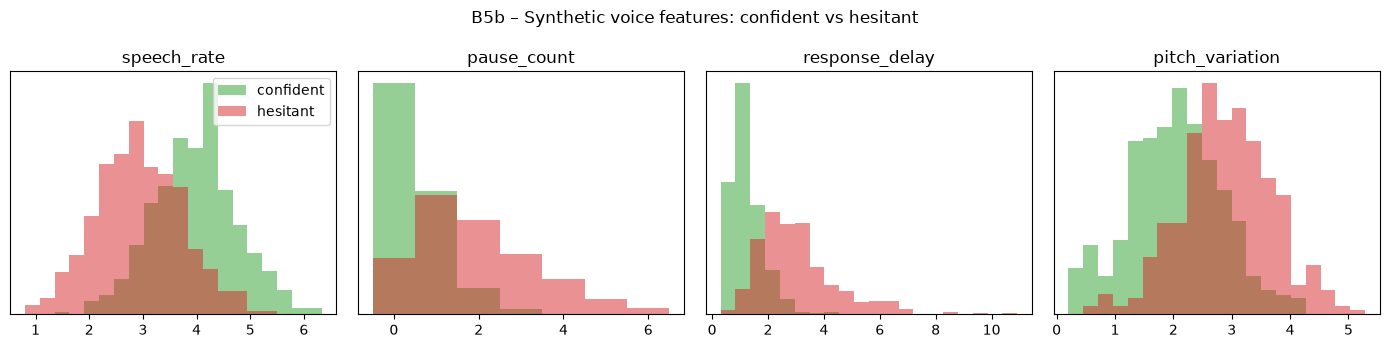

In [35]:
# Distribution of every feature for the two states (overlap = some answers are hard to judge)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, feature in zip(axes, CONFIDENCE_FEATURES):
    # Same bins for both states so the bars line up; whole-number bins for the count feature
    if feature == "pause_count":
        bins = np.arange(-0.5, b5b_df[feature].max() + 1.5, 1)
    else:
        bins = np.histogram_bin_edges(b5b_df[feature], bins=20)
    for state, color in [("confident", "tab:green"), ("hesitant", "tab:red")]:
        values = b5b_df.loc[b5b_df["state"] == state, feature]
        ax.hist(values, bins=bins, alpha=0.5, color=color, label=state, density=True)
    ax.set_title(feature)
    ax.set_yticks([])
axes[0].legend()
fig.suptitle("B5b – Synthetic voice features: confident vs hesitant")
plt.tight_layout()
save_figure(fig, "b5b_feature_distributions.png")
plt.show()

### B5b.2 Preprocessing

- **Missing values:** none in this synthetic table (checked below).
- **Scaling is needed:** Logistic Regression is sensitive to feature scales (seconds, counts, semitones).
  `StandardScaler` (inside the Pipeline, fitted on training data only) also makes the learned coefficients
  **comparable**, so we can read which feature indicates hesitation most strongly.

In [36]:
print("Missing values in the whole table:", b5b_df[CONFIDENCE_FEATURES].isna().sum().sum())

X_b5b = b5b_df[CONFIDENCE_FEATURES]
y_b5b = b5b_df["state"]

Missing values in the whole table: 0


### B5b.3 Train / test split

80% training, 20% test. `stratify` keeps the 60/40 class ratio in both parts – important for imbalanced classes.

In [37]:
X_b5b_train, X_b5b_test, y_b5b_train, y_b5b_test = train_test_split(
    X_b5b, y_b5b, test_size=0.2, stratify=y_b5b, random_state=RANDOM_STATE)

print("Training set:", X_b5b_train.shape, " Test set:", X_b5b_test.shape)
print("Share of 'hesitant' -> train:", round((y_b5b_train == "hesitant").mean(), 3),
      " test:", round((y_b5b_test == "hesitant").mean(), 3))

Training set: (800, 4)  Test set: (200, 4)
Share of 'hesitant' -> train: 0.4  test: 0.4


### B5b.4 Model

**StandardScaler → LogisticRegression.** For two classes, Logistic Regression computes a weighted sum of the
(scaled) features and turns it into a probability between 0 and 1 with the sigmoid function:
P(hesitant) = 1 / (1 + e^-(w1·speech_rate + w2·pause_count + w3·response_delay + w4·pitch_variation + b)).
If P(hesitant) ≥ 0.5 the answer is classified as hesitant.

In [38]:
b5b_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
b5b_model.fit(X_b5b_train, y_b5b_train)
print("B5b model trained. Classes:", list(b5b_model.classes_))

B5b model trained. Classes: ['confident', 'hesitant']


### B5b.5 Evaluation

- Training vs test accuracy (overfitting check)
- Classification report and confusion matrix
- **Coefficients:** a positive coefficient pushes the prediction towards `hesitant`, a negative one towards
  `confident`; the larger the absolute value, the stronger the feature (features are scaled, so they are comparable).

Training accuracy: 0.931
Test accuracy:     0.935

              precision    recall  f1-score   support

   confident       0.93      0.96      0.95       120
    hesitant       0.94      0.90      0.92        80

    accuracy                           0.94       200
   macro avg       0.94      0.93      0.93       200
weighted avg       0.94      0.94      0.93       200



Figure saved: outputs/b5b_confusion_matrix.png


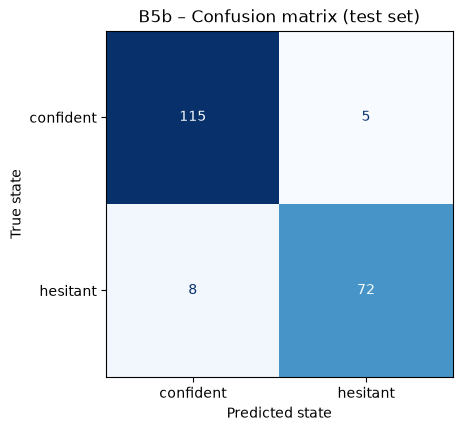

In [39]:
b5b_train_accuracy = accuracy_score(y_b5b_train, b5b_model.predict(X_b5b_train))
y_b5b_pred = b5b_model.predict(X_b5b_test)
b5b_accuracy = accuracy_score(y_b5b_test, y_b5b_pred)

print(f"Training accuracy: {b5b_train_accuracy:.3f}")
print(f"Test accuracy:     {b5b_accuracy:.3f}\n")
print(classification_report(y_b5b_test, y_b5b_pred))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_b5b_test, y_b5b_pred, labels=["confident", "hesitant"]),
                       display_labels=["confident", "hesitant"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B5b – Confusion matrix (test set)")
ax.set_xlabel("Predicted state")
ax.set_ylabel("True state")
save_figure(fig, "b5b_confusion_matrix.png")
plt.show()

Coefficients (positive -> more hesitant):
speech_rate       -1.497
pitch_variation    1.188
pause_count        1.474
response_delay     2.734
Figure saved: outputs/b5b_coefficients.png


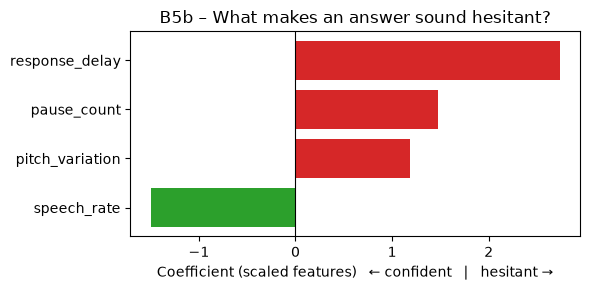

In [40]:
coefficients = pd.Series(b5b_model.named_steps["classifier"].coef_[0],
                         index=CONFIDENCE_FEATURES).sort_values()
print("Coefficients (positive -> more hesitant):")
print(coefficients.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
bar_colors = ["tab:green" if c < 0 else "tab:red" for c in coefficients.values]
ax.barh(coefficients.index, coefficients.values, color=bar_colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (scaled features)   ← confident   |   hesitant →")
ax.set_title("B5b – What makes an answer sound hesitant?")
plt.tight_layout()
save_figure(fig, "b5b_coefficients.png")
plt.show()

### B5b.6 Example prediction – two ways of saying "nine"

The tutor asks *"4 + 5 = ?"*. We compare two spoken answers with the same words but a different voice.

In [41]:
can_answers = pd.DataFrame([
    {"speech_rate": 4.3, "pause_count": 0, "response_delay": 0.9, "pitch_variation": 1.8},   # "Nine!"
    {"speech_rate": 2.4, "pause_count": 3, "response_delay": 3.5, "pitch_variation": 3.6},   # "Hmm... nine?"
], index=['"Nine!"', '"Hmm... nine?"'])

hesitant_column = list(b5b_model.classes_).index("hesitant")
for answer, row in can_answers.iterrows():
    x = row.to_frame().T
    b5b_output = {"state": b5b_model.predict(x)[0],
                  "p_hesitant": round(float(b5b_model.predict_proba(x)[0][hesitant_column]), 3)}
    print(f"{answer:16s} -> B5b output: {b5b_output}")

"Nine!"          -> B5b output: {'state': 'confident', 'p_hesitant': 0.003}
"Hmm... nine?"   -> B5b output: {'state': 'hesitant', 'p_hesitant': 1.0}


### B5b.7 Block function (used by the end-to-end demo)

In [42]:
def b5b_detect_confidence(speech_rate, pause_count, response_delay, pitch_variation):
    # Input : four voice features of one spoken answer
    # Output: {"state": "confident"/"hesitant", "p_hesitant": probability of hesitation}
    x = pd.DataFrame([{"speech_rate": speech_rate, "pause_count": pause_count,
                       "response_delay": response_delay, "pitch_variation": pitch_variation}], dtype=float)
    p_hesitant = float(b5b_model.predict_proba(x)[0][list(b5b_model.classes_).index("hesitant")])
    return {"state": "hesitant" if p_hesitant >= 0.5 else "confident",
            "p_hesitant": round(p_hesitant, 3)}


print("b5b_detect_confidence ->", b5b_detect_confidence(2.4, 3, 3.5, 3.6))

b5b_detect_confidence -> {'state': 'hesitant', 'p_hesitant': 1.0}


---
## Text Blocks – B1 (Interest), B2 (Struggle Topic) and their Sentiment Output

At the start of every session Math Buddy chats with Can (*"What did you do today?"*, *"Which topic is hard for you?"*).
From each message the tutor extracts:

| Block | Question | Output |
|---|---|---|
| **B1** | What is Can interested in? | `interest` ∈ {sports, animals, food, games} **+ `sentiment`** |
| **B2** | Which math topic does Can struggle with? | `topic` ∈ {addition, subtraction, multiplication, division, fractions} **+ `sentiment`** |

**Why sentiment?** *"I love football"* and *"I hate football"* are both about sports. Without sentiment the tutor
would build football problems for a child who hates football. So both blocks also return the **sentiment**
(`positive` / `neutral` / `negative`) of the message, and the tutor only uses interests that are not negative.
For B2, a negative message (*"I hate fractions"*) tells the tutor to start with easier, more playful problems.

### Text data (synthetic)

There is no public dataset of children's chat messages with these labels, so we **generate** messages from
**templates and word pools** (e.g. template *"I {activity} today and it was so much fun!"* + activity *"played football"*).
To make the data realistic and not trivially easy:
- some words appear in several classes (*"played"* football / chess / with my cat),
- some messages contain a second sentence about another interest (*"Then I ate pizza."*),
- some B2 messages mention two topics (*"I can do addition but division is so hard"*),
- every template has variable parts (when, with whom, an opener such as *"Guess what?"*, an ending such as *":)"*),
  so one template produces many different sentences,
- a few words have typos (a missing letter),
- some sentiment templates share words (*"is so boring"* vs *"is not boring at all"*, *"my favorite"* vs
  *"not my favorite"*), and **8% of the sentiment labels are changed at random** – in reality people who label
  short messages often disagree (annotator disagreement), so a perfect score would be unrealistic,
- **duplicate messages are removed**, otherwise the same sentence could appear in both the training and the
  test set and the accuracy would be too optimistic (a form of leakage).

In [43]:
text_rng = np.random.default_rng(RANDOM_STATE)

# ---------- B1 word pools: (noun phrase, past-tense activity) for every interest ----------
INTEREST_ITEMS = {
    "sports":  [("football", "played football"), ("basketball", "played basketball"),
                ("tennis", "played tennis"), ("swimming", "went swimming"),
                ("volleyball", "played volleyball"), ("running", "went running in the park"),
                ("cycling", "rode my bike"), ("the football match", "watched the football match"),
                ("my team", "trained with my team"), ("karate", "went to karate class"),
                ("baseball", "played baseball"), ("gymnastics", "went to gymnastics"),
                ("the race", "ran a race at school"), ("ice skating", "went ice skating"),
                ("handball", "played handball with my class")],
    "animals": [("my cat", "played with my cat"), ("my dog", "walked my dog"),
                ("puppies", "played with the puppies"), ("horses", "fed the horses"),
                ("the zoo", "went to the zoo"), ("my rabbit", "fed my rabbit"),
                ("parrots", "watched the parrots"), ("my hamster", "cleaned my hamster's cage"),
                ("farm animals", "visited the farm animals"), ("fish", "fed the fish in our aquarium"),
                ("turtles", "watched the turtles at the pond"), ("my puppy", "taught my puppy a new trick"),
                ("ducks", "fed the ducks"), ("the aquarium", "visited the aquarium"),
                ("my kitten", "brushed my kitten")],
    "food":    [("pizza", "ate pizza"), ("pancakes", "made pancakes"), ("ice cream", "had ice cream"),
                ("chocolate cake", "baked a chocolate cake"), ("cookies", "baked cookies with mom"),
                ("pasta", "cooked pasta"), ("burgers", "ate burgers"),
                ("strawberries", "picked strawberries"), ("lunch at grandma's", "had lunch at grandma's"),
                ("fruit salad", "made a fruit salad"), ("sandwiches", "made sandwiches"),
                ("popcorn", "ate popcorn"), ("soup", "had soup for dinner"),
                ("muffins", "baked muffins"), ("smoothies", "made a banana smoothie")],
    "games":   [("Minecraft", "played Minecraft"), ("chess", "played chess"),
                ("video games", "played video games"), ("board games", "played board games"),
                ("puzzles", "did a puzzle"), ("Lego", "built a Lego castle"),
                ("hide and seek", "played hide and seek"), ("card games", "played card games"),
                ("my new game", "played my new game on the tablet"), ("Roblox", "played Roblox"),
                ("tag", "played tag"), ("dominoes", "played dominoes"),
                ("the treasure hunt", "did a treasure hunt"), ("my console", "played on my console"),
                ("memory games", "played a memory game")],
}

# ---------- Variable parts that make every template produce many different sentences ----------
WHEN = ["today", "yesterday", "this morning", "after school", "on Saturday", "at the weekend",
        "in the afternoon", "last night"]
WHO = ["with my friends", "with my brother", "with my sister", "with dad", "with mom",
       "with my cousin", "with my best friend", "with my class", "alone"]
B1_OPENERS = ["", "", "", "Guess what? ", "Hmm, ", "Well, ", "You know what? ", "Hey! ", "Oh, "]
ENDINGS = ["", "", "!", ".", " :)", " haha", "!!"]

B1_TEMPLATES = {
    "positive": ["I love {noun}", "{Noun} is my favorite thing", "I {activity} {when} and it was so much fun",
                 "I {activity} {who}, it was awesome", "I {activity} {when} and I can't wait to do it again",
                 "{Noun} is never boring", "I never get tired of {noun}", "Best day ever, I {activity} {who}",
                 "{Noun} is not boring at all", "{Noun} is my favorite, I don't want to stop",
                 "I really like {noun}", "{Noun} makes me so happy", "I {activity} {when}, it was the best",
                 "I had a great time, I {activity} {who}", "Nothing is better than {noun}",
                 "I want to do it every day, I love {noun}"],
    "negative": ["I hate {noun}", "{Noun} is so boring", "I don't like {noun}",
                 "I {activity} {when} and it was terrible", "I can't stand {noun}",
                 "I {activity} {when} and I never want to do it again", "{Noun} is not fun at all",
                 "I {activity} {who} but I didn't enjoy it", "{Noun} is not my favorite thing",
                 "I don't love {noun} anymore", "I wanted to have fun but {noun} was boring",
                 "I {activity} {when}, it was the worst", "{Noun} makes me so sad",
                 "I had a bad day, I {activity} {who} and it was awful", "I really don't want {noun} again",
                 "Mom made me do it, I {activity} {when} and it was boring"],
    "neutral":  ["I {activity} {when}", "I {activity} {who}", "{When} I {activity}", "{When} I {activity} {who}",
                 "We {activity} {when}", "My sister and I {activity}", "First I did my homework, then I {activity}",
                 "I {activity} {when}, then I went home", "I think I {activity} {when}",
                 "Dad said I can choose, so I {activity}", "I {activity} {who} {when}", "Nothing special, I {activity}"],
}
SECOND_SENTENCE = [" Then I {activity}.", " After that I {activity}.", " Later we {activity}."]

# ---------- B2 word pools ----------
STRUGGLE_ITEMS = {
    "addition":       ["addition", "adding numbers", "plus problems", "carrying in addition",
                       "adding big numbers", "sums", "adding with carrying", "two-digit addition",
                       "adding three numbers", "word problems with plus"],
    "subtraction":    ["subtraction", "taking away", "minus problems", "borrowing in subtraction",
                       "subtracting big numbers", "take-away sums", "subtracting with zeros",
                       "two-digit subtraction", "finding the difference", "word problems with minus"],
    "multiplication": ["multiplication", "the times tables", "multiplying", "the 7 times table",
                       "times problems", "multiplying by 9", "multiplying big numbers",
                       "the 6 and 8 times tables", "double-digit multiplication", "repeated addition"],
    "division":       ["division", "dividing", "sharing things equally", "long division",
                       "dividing by 3", "division with remainders", "dividing big numbers",
                       "remainders", "dividing by 7", "splitting things into groups"],
    "fractions":      ["fractions", "halves and quarters", "adding fractions",
                       "the numerator and denominator", "comparing fractions", "a third of a number",
                       "mixed numbers", "equivalent fractions", "fractions of a pizza", "simplifying fractions"],
}

B2_OPENERS = ["", "", "", "Teacher, ", "Math Buddy, ", "Hmm, ", "Um, "]
B2_CONTRAST = ["I can do {other} but ", "{Other} is easy, but ", "I'm good at {other}, but "]

B2_TEMPLATES = {
    "negative": ["I don't understand {x} at all", "{X} is so hard", "I hate {x}", "I always get {x} wrong",
                 "I'm so confused about {x}", "My teacher gave us {x} homework and I couldn't do it",
                 "I never get {x} right", "{X} makes my head hurt", "I cried during {x} {when}",
                 "Everyone else understands {x} but I don't", "I don't get {x}, it's too difficult",
                 "{X} is the worst part of math"],
    "neutral":  ["Can you help me with {x}?", "{When} at school we learned {x}",
                 "We have a test on {x} tomorrow", "Can we practice {x}?", "What is {x}?",
                 "Our teacher said we start {x} next week", "Is {x} on the test?",
                 "I have {x} homework {when}", "Can you show me how {x} works?"],
    "positive": ["I like {x} but the last question was hard", "{X} is fun but I still make mistakes",
                 "I'm getting better at {x} but I need more practice",
                 "{X} is getting easier but I still need help", "I love {x} but some questions are tricky",
                 "I want to be really good at {x}, can we practice more?", "I got most of {x} right but not all"],
}


def capitalize(text):
    return text[0].upper() + text[1:]


def decapitalize(text):
    # lower-case the first letter, but keep "I" / "I'm" as they are
    return text if text.startswith("I ") or text.startswith("I'") else text[0].lower() + text[1:]


def with_opener(opener, sentence):
    # "Hmm, " + "Pizza is ..." -> "Hmm, pizza is ..." ; "Guess what? " keeps the capital letter
    return opener + (decapitalize(sentence) if opener.endswith(", ") else sentence)


def add_typos(message, rng, rate=0.04):
    # Drop one random letter from some longer words (children make spelling mistakes)
    words = message.split(" ")
    for i, word in enumerate(words):
        if len(word) > 4 and rng.random() < rate:
            j = rng.integers(1, len(word) - 1)
            words[i] = word[:j] + word[j + 1:]
    return " ".join(words)


def generate_b1_messages(n_per_interest, rng):
    rows = []
    interests = list(INTEREST_ITEMS)
    for interest in interests:
        for _ in range(n_per_interest):
            sentiment = str(rng.choice(["positive", "negative", "neutral"], p=[0.40, 0.25, 0.35]))
            noun, activity = INTEREST_ITEMS[interest][rng.integers(len(INTEREST_ITEMS[interest]))]
            when = str(rng.choice(WHEN))
            sentence = str(rng.choice(B1_TEMPLATES[sentiment])).format(
                noun=noun, Noun=capitalize(noun), activity=activity,
                when=when, When=capitalize(when), who=str(rng.choice(WHO)))
            message = with_opener(str(rng.choice(B1_OPENERS)), sentence) + str(rng.choice(ENDINGS))
            if rng.random() < 0.15:     # a second, neutral sentence about another interest (confusing cue)
                other = rng.choice([i for i in interests if i != interest])
                other_activity = INTEREST_ITEMS[other][rng.integers(len(INTEREST_ITEMS[other]))][1]
                message += str(rng.choice(SECOND_SENTENCE)).format(activity=other_activity)
            rows.append({"message": add_typos(message, rng), "interest": interest, "sentiment": sentiment})
    return pd.DataFrame(rows)


def generate_b2_messages(n_per_topic, rng):
    rows = []
    topics = list(STRUGGLE_ITEMS)
    for topic in topics:
        for _ in range(n_per_topic):
            sentiment = str(rng.choice(["negative", "neutral", "positive"], p=[0.55, 0.30, 0.15]))
            phrase = str(rng.choice(STRUGGLE_ITEMS[topic]))
            when = str(rng.choice(WHEN))
            message = str(rng.choice(B2_TEMPLATES[sentiment])).format(
                x=phrase, X=capitalize(phrase), when=when, When=capitalize(when))
            if rng.random() < 0.20:     # mentions another topic the child CAN do (confusing cue)
                other = str(rng.choice(STRUGGLE_ITEMS[str(rng.choice([t for t in topics if t != topic]))]))
                contrast = str(rng.choice(B2_CONTRAST)).format(other=other, Other=capitalize(other))
                message = contrast + decapitalize(message)
            message = with_opener(str(rng.choice(B2_OPENERS)), message)
            rows.append({"message": add_typos(message, rng), "topic": topic, "sentiment": sentiment})
    return pd.DataFrame(rows)


def add_sentiment_label_noise(df, rng, rate=0.08):
    # Annotators do not always agree on the sentiment of a short message -> change ~8% of the labels at random
    df = df.copy()
    flip = rng.random(len(df)) < rate
    df.loc[flip, "sentiment"] = [str(rng.choice([s for s in ["positive", "neutral", "negative"] if s != old]))
                                 for old in df.loc[flip, "sentiment"]]
    return df


def drop_duplicate_messages(df, name):
    before = len(df)
    df = df.drop_duplicates(subset="message").reset_index(drop=True)
    print(f"{name}: generated {before} messages, removed {before - len(df)} duplicates -> {len(df)} unique")
    return df


b1_df = add_sentiment_label_noise(drop_duplicate_messages(generate_b1_messages(400, text_rng), "B1"), text_rng)
b2_df = add_sentiment_label_noise(drop_duplicate_messages(generate_b2_messages(300, text_rng), "B2"), text_rng)

B1: generated 1600 messages, removed 3 duplicates -> 1597 unique


B2: generated 1500 messages, removed 108 duplicates -> 1392 unique


---
## Block B1 – Interest Detection (Supervised · Text)

- **Task:** multi-class text classification (4 classes)
- **Input structure:** `message` – one chat message written by the child (free English text)
- **Label:** `interest` ∈ {sports, animals, food, games}
- **Output structure:** predicted `interest` + probability (+ `sentiment`, see the Sentiment section)
- **Real-data alternative:** children's chat logs collected by the app (with consent), labelled by teachers;
  general hobby corpora such as the Yellowbrick *hobbies* corpus are adult texts and do not fit well.

### B1.1 Data

In [44]:
print("Messages per interest:", b1_df["interest"].value_counts().to_dict())
print("Messages per sentiment:", b1_df["sentiment"].value_counts().to_dict())
print("\nRandom examples:")
print(b1_df.sample(8, random_state=RANDOM_STATE).to_string(index=False))

Messages per interest: {'food': 400, 'games': 400, 'sports': 399, 'animals': 398}
Messages per sentiment: {'positive': 649, 'neutral': 542, 'negative': 406}

Random examples:
                                                       message interest sentiment
      Hmm, I made sandwiches last night and it was so much fun     food  positive
                            Well, volleyball is not fun at all   sports  negative
     You know what? I want to do it every day, I love karate!!   sports  positive
                               I fed my rabbit with my cousin.  animals   neutral
                   You know what? I never get tired of Roblox!    games  positive
 Burgers is my fvorite thing! Then I went running in the park.     food  positive
Well, I played board games on Saturday and it was so much fun.    games  positive
    You know what? This morning I cleaned my hamster's cage :)  animals   neutral


### B1.2 Preprocessing – TF-IDF

A model needs numbers, not text. **TF-IDF** turns every message into a vector with one column per word of
the vocabulary:
- **TF (term frequency):** how often the word appears in this message,
- **IDF (inverse document frequency):** how *rare* the word is across all messages – words that appear
  everywhere (*"I"*, *"my"*, *"today"*) get a low weight, distinctive words (*"football"*, *"pizza"*) a high weight,
- **TF-IDF = TF × IDF.**

`TfidfVectorizer` also lower-cases the text and splits it into words. It **learns the vocabulary and the IDF
weights from the training messages only** (it is the first step of the Pipeline), so no information from the
test messages leaks into the model. Words that never appeared in training are ignored at prediction time.

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_b1 = b1_df["message"]
y_b1 = b1_df["interest"]

# Small illustration on three messages: which words get high TF-IDF weights?
demo_vectorizer = TfidfVectorizer()
demo_matrix = demo_vectorizer.fit_transform(["I played football with my friends",
                                             "I ate pizza with my friends",
                                             "I played with my cat"])
print(pd.DataFrame(demo_matrix.toarray().round(2), columns=demo_vectorizer.get_feature_names_out(),
                   index=["msg 1", "msg 2", "msg 3"]).to_string())
print("\nNote: 'with', 'my', 'friends' appear in several messages -> lower weight;"
      " 'football', 'pizza', 'cat' appear once -> higher weight.")
print("('I' is dropped because the default tokenizer ignores one-letter words.)")

        ate   cat  football  friends    my  pizza  played  with
msg 1  0.00  0.00      0.59     0.45  0.35   0.00    0.45  0.35
msg 2  0.55  0.00      0.00     0.42  0.33   0.55    0.00  0.33
msg 3  0.00  0.66      0.00     0.00  0.39   0.00    0.50  0.39

Note: 'with', 'my', 'friends' appear in several messages -> lower weight; 'football', 'pizza', 'cat' appear once -> higher weight.
('I' is dropped because the default tokenizer ignores one-letter words.)


### B1.3 Train / test split

80% training, 20% test, stratified by interest.

In [46]:
X_b1_train, X_b1_test, y_b1_train, y_b1_test = train_test_split(
    X_b1, y_b1, test_size=0.2, stratify=y_b1, random_state=RANDOM_STATE)
print("Training messages:", len(X_b1_train), " Test messages:", len(X_b1_test))

Training messages: 1277  Test messages: 320


### B1.4 Model

**TfidfVectorizer → LogisticRegression.** The Logistic Regression learns one weight per (word, class):
a large positive weight means "this word points to this class".

In [47]:
b1_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
b1_model.fit(X_b1_train, y_b1_train)
print("B1 model trained. Vocabulary size:", len(b1_model.named_steps["tfidf"].vocabulary_))

B1 model trained. Vocabulary size: 349


### B1.5 Evaluation

Training accuracy: 0.934
Test accuracy:     0.884

              precision    recall  f1-score   support

     animals       0.93      0.81      0.87        80
        food       0.88      0.91      0.90        80
       games       0.86      0.94      0.90        80
      sports       0.88      0.88      0.88        80

    accuracy                           0.88       320
   macro avg       0.89      0.88      0.88       320
weighted avg       0.89      0.88      0.88       320

Figure saved: outputs/b1_confusion_matrix.png


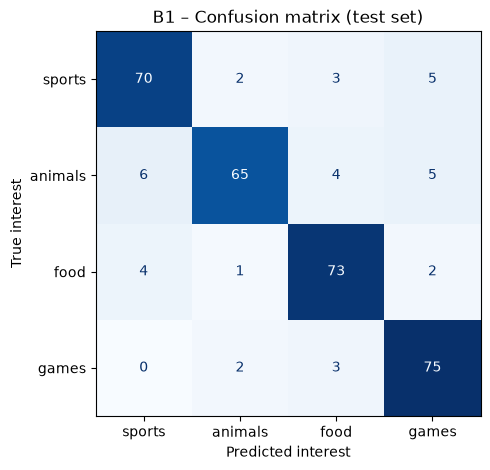

Some of the 37 misclassified test messages:
                                                                              message    true predicted
      You know what? I don't love my puppy anymore After that I played hide and seek. animals     games
                I don't like gymnastics After that I watched the turtles at the pond.  sports   animals
Hmm, horses is my favorite, I don't want to stop After that I had lunch at grandma's. animals      food
                   You know what? My dog is not boring at all. Later we did a puzzle. animals     games
                       On Saturday I pcked strawberries! Then I trained with my team.    food    sports
                                            I hate puppies. Then I played basketball. animals    sports


In [48]:
b1_train_accuracy = accuracy_score(y_b1_train, b1_model.predict(X_b1_train))
y_b1_pred = b1_model.predict(X_b1_test)
b1_accuracy = accuracy_score(y_b1_test, y_b1_pred)
print(f"Training accuracy: {b1_train_accuracy:.3f}")
print(f"Test accuracy:     {b1_accuracy:.3f}\n")
print(classification_report(y_b1_test, y_b1_pred))

interest_order = list(INTEREST_ITEMS)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_b1_test, y_b1_pred, labels=interest_order),
                       display_labels=interest_order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("B1 – Confusion matrix (test set)")
ax.set_xlabel("Predicted interest")
ax.set_ylabel("True interest")
save_figure(fig, "b1_confusion_matrix.png")
plt.show()

# Show some test messages the model got wrong (useful for the report)
mistakes = pd.DataFrame({"message": X_b1_test, "true": y_b1_test, "predicted": y_b1_pred})
mistakes = mistakes[mistakes["true"] != mistakes["predicted"]]
print(f"Some of the {len(mistakes)} misclassified test messages:")
print(mistakes.head(6).to_string(index=False))

Figure saved: outputs/b1_top_words.png


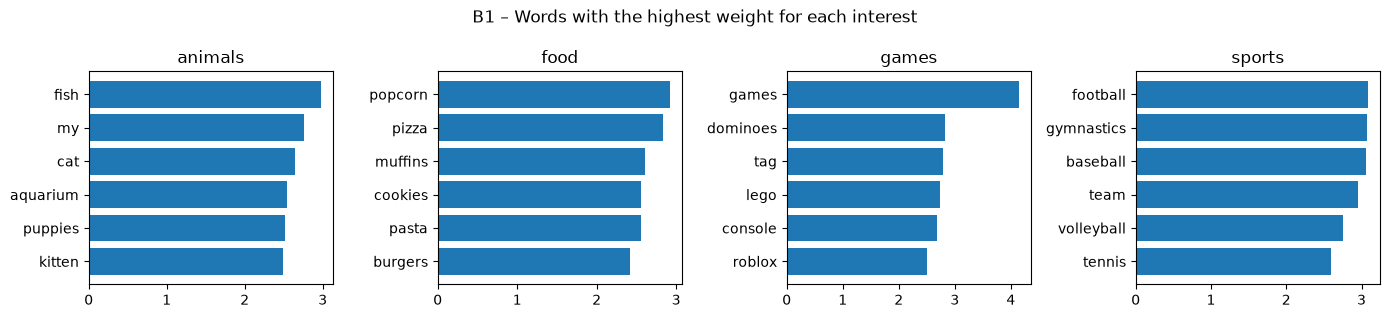

In [49]:
# Which words does the model rely on? Top 6 words with the largest weight for every interest
vocabulary = b1_model.named_steps["tfidf"].get_feature_names_out()
weights = b1_model.named_steps["classifier"].coef_            # shape: (n_classes, n_words)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, class_name, class_weights in zip(axes, b1_model.classes_, weights):
    top = np.argsort(class_weights)[-6:]
    ax.barh(vocabulary[top], class_weights[top], color="tab:blue")
    ax.set_title(class_name)
fig.suptitle("B1 – Words with the highest weight for each interest")
plt.tight_layout()
save_figure(fig, "b1_top_words.png")
plt.show()

---
## Block B2 – Struggle Topic Detection (Supervised · Text)

- **Task:** multi-class text classification (5 classes)
- **Input structure:** `message` – what the child writes about math (*"I don't get the times tables"*)
- **Label:** `topic` ∈ {addition, subtraction, multiplication, division, fractions}
- **Output structure:** predicted `topic` + probability (+ `sentiment`)
- **Real-data note:** ASDiv / SVAMP contain elementary math *word problems* labelled by operation, but not
  children's messages about their difficulties, so they do not match this block directly.

Steps 1–5 follow exactly the same pattern as B1.

In [50]:
print("Messages per topic:", b2_df["topic"].value_counts().to_dict())
print("\nRandom examples:")
print(b2_df.sample(8, random_state=RANDOM_STATE).to_string(index=False))

X_b2 = b2_df["message"]
y_b2 = b2_df["topic"]
X_b2_train, X_b2_test, y_b2_train, y_b2_test = train_test_split(
    X_b2, y_b2, test_size=0.2, stratify=y_b2, random_state=RANDOM_STATE)
print("\nTraining messages:", len(X_b2_train), " Test messages:", len(X_b2_test))

Messages per topic: {'multiplication': 282, 'subtraction': 279, 'division': 279, 'addition': 277, 'fractions': 275}

Random examples:
                                                                                          message       topic sentiment
                           The 6 and 8 times tables is easy, but dividing by 7 makes my head hurt    division  negative
                                        Math Buddy, can you help me with word problems with plus?    addition   neutral
                                                          Mixed numbers is the worst part of math   fractions  negative
                                               Um, can you show me how dividing big numbers woks?    division   neutral
                                                       Teacher, can you help me with subtraction? subtraction   neutral
                                                              Um, fractions of a pizza is so hard   fractions  negative
Math Buddy, I can do the 6


Training messages: 1113  Test messages: 279


Training accuracy: 0.930
Test accuracy:     0.892

                precision    recall  f1-score   support

      addition       0.91      0.93      0.92        55
      division       0.91      0.86      0.88        56
     fractions       0.89      0.91      0.90        55
multiplication       0.88      0.89      0.89        57
   subtraction       0.88      0.88      0.88        56

      accuracy                           0.89       279
     macro avg       0.89      0.89      0.89       279
  weighted avg       0.89      0.89      0.89       279

Figure saved: outputs/b2_confusion_matrix.png


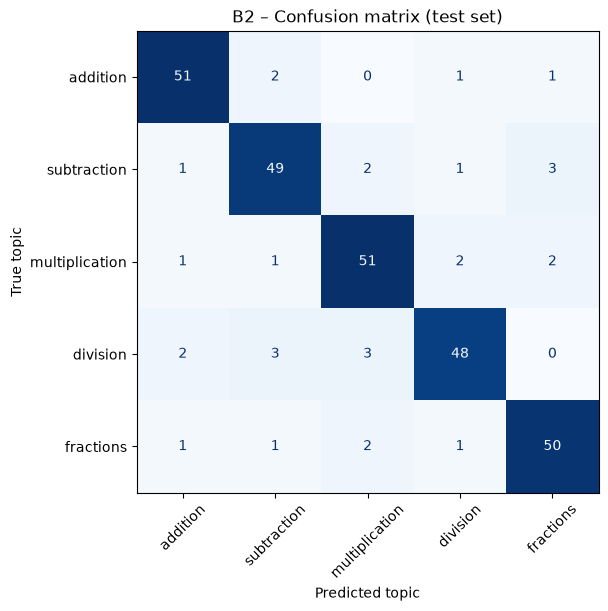

Some of the 30 misclassified test messages:
                                                                                                   message           true      predicted
                            Long division is easy, but I cried during subtracting big numbers this morning    subtraction       division
Math Buddy, I'm good at double-digit multiplication, but can you show me how finding the difference works?    subtraction multiplication
          Hmm, I'm good at subtracting big numbers, but our teacher said we start multiplication next week multiplication    subtraction
Hmm, I'm good at two-digit addition, but my teacher gave us repeated addition homework and I coudn't do it multiplication       addition
                                                      Um, I can do the 7 times table but what is division?       division multiplication
I'm good at the 7 times table, but my teacher gave us subtracting with zeros homework and I couldn't do it    subtraction multiplicati

In [51]:
b2_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
b2_model.fit(X_b2_train, y_b2_train)

b2_train_accuracy = accuracy_score(y_b2_train, b2_model.predict(X_b2_train))
y_b2_pred = b2_model.predict(X_b2_test)
b2_accuracy = accuracy_score(y_b2_test, y_b2_pred)
print(f"Training accuracy: {b2_train_accuracy:.3f}")
print(f"Test accuracy:     {b2_accuracy:.3f}\n")
print(classification_report(y_b2_test, y_b2_pred))

topic_order = list(STRUGGLE_ITEMS)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_b2_test, y_b2_pred, labels=topic_order),
                       display_labels=topic_order).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("B2 – Confusion matrix (test set)")
ax.set_xlabel("Predicted topic")
ax.set_ylabel("True topic")
save_figure(fig, "b2_confusion_matrix.png")
plt.show()

mistakes = pd.DataFrame({"message": X_b2_test, "true": y_b2_test, "predicted": y_b2_pred})
mistakes = mistakes[mistakes["true"] != mistakes["predicted"]]
print(f"Some of the {len(mistakes)} misclassified test messages:")
print(mistakes.head(6).to_string(index=False))

---
## Sentiment – the second output of B1 and B2 (Supervised · Text)

- **Task:** 3-class text classification: `positive` / `neutral` / `negative`
- **Training data:** all B1 and B2 messages together (both have a `sentiment` label), so one model works for
  chat about hobbies *and* about math.
- **Model:** TF-IDF → Logistic Regression.

**The negation problem.** TF-IDF looks at single words and ignores their order. In *"Chess is not boring at all"*
the single word *boring* points to negative, and in *"Chess is not my favorite"* the word *favorite* points to
positive – only the **word pair** (*"not boring"*, *"not my"*) reveals the real sentiment. With `ngram_range=(1, 2)`
TF-IDF also creates features for pairs of neighbouring words (**bigrams**). We compare both versions.

Note: the default tokenizer splits *"can't"* into *"can"* and *"t"* and drops the one-letter *"t"*.

In [52]:
sentiment_df = pd.concat([b1_df[["message", "sentiment"]], b2_df[["message", "sentiment"]]],
                         ignore_index=True)
print("Messages per sentiment:", sentiment_df["sentiment"].value_counts().to_dict())

X_sent_train, X_sent_test, y_sent_train, y_sent_test = train_test_split(
    sentiment_df["message"], sentiment_df["sentiment"],
    test_size=0.2, stratify=sentiment_df["sentiment"], random_state=RANDOM_STATE)

ngram_results = {}
for name, ngram_range in [("single words (1,1)", (1, 1)), ("words + word pairs (1,2)", (1, 2))]:
    model = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram_range)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]).fit(X_sent_train, y_sent_train)
    ngram_results[name] = model
    print(f"{name:26s} test accuracy: {accuracy_score(y_sent_test, model.predict(X_sent_test)):.3f}")

# Tricky negation examples (not in the generated data in exactly this form)
tricky = ["Chess is not boring at all", "Chess is so boring",
          "Chess is my favorite", "Chess is not my favorite",
          "I love my dog", "I don't love my dog anymore"]
comparison = pd.DataFrame({"message": tricky})
for name, model in ngram_results.items():
    comparison[name] = model.predict(tricky)
print("\nNegation examples:")
print(comparison.to_string(index=False))

Messages per sentiment: {'negative': 1137, 'neutral': 967, 'positive': 885}
single words (1,1)         test accuracy: 0.893


words + word pairs (1,2)   test accuracy: 0.905

Negation examples:
                    message single words (1,1) words + word pairs (1,2)
 Chess is not boring at all           positive                 positive
         Chess is so boring           positive                 negative
       Chess is my favorite           positive                 positive
   Chess is not my favorite           negative                 negative
              I love my dog           positive                 positive
I don't love my dog anymore           negative                 negative


We keep the **(1, 2)** version as the sentiment model.

              precision    recall  f1-score   support

    negative       0.92      0.93      0.92       228
     neutral       0.91      0.89      0.90       193
    positive       0.89      0.89      0.89       177

    accuracy                           0.90       598
   macro avg       0.90      0.90      0.90       598
weighted avg       0.90      0.90      0.90       598



Figure saved: outputs/sentiment_confusion_matrix.png


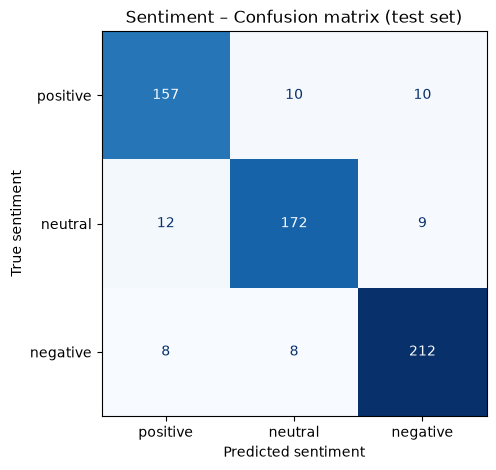

In [53]:
sentiment_model = ngram_results["words + word pairs (1,2)"]
y_sent_pred = sentiment_model.predict(X_sent_test)
print(classification_report(y_sent_test, y_sent_pred))

sentiment_order = ["positive", "neutral", "negative"]
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_sent_test, y_sent_pred, labels=sentiment_order),
                       display_labels=sentiment_order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Sentiment – Confusion matrix (test set)")
ax.set_xlabel("Predicted sentiment")
ax.set_ylabel("True sentiment")
save_figure(fig, "sentiment_confusion_matrix.png")
plt.show()

### B1 / B2 – Example predictions and block functions

**Tutor rule:** an interest is used for personalized word problems only if its sentiment is **not negative**.
For B2, a negative message makes the tutor start with easier problems.

The last B1 example uses the word *"soccer"*, which never appears in the training data – it shows a limitation
of TF-IDF (unknown words are ignored). A pretrained language model such as **DistilBERT** knows that
*soccer* ≈ *football* and would handle it (future work).

In [54]:
def b1_analyze_message(message):
    # Input : one chat message
    # Output: {"interest", "probability", "sentiment", "use_for_problems"}
    probabilities = b1_model.predict_proba([message])[0]
    best = int(np.argmax(probabilities))
    sentiment = str(sentiment_model.predict([message])[0])
    return {"interest": str(b1_model.classes_[best]),
            "probability": round(float(probabilities[best]), 3),
            "sentiment": sentiment,
            "use_for_problems": sentiment != "negative"}


def b2_analyze_message(message):
    # Input : one message about math
    # Output: {"topic", "probability", "sentiment", "start_easy"}
    probabilities = b2_model.predict_proba([message])[0]
    best = int(np.argmax(probabilities))
    sentiment = str(sentiment_model.predict([message])[0])
    return {"topic": str(b2_model.classes_[best]),
            "probability": round(float(probabilities[best]), 3),
            "sentiment": sentiment,
            "start_easy": sentiment == "negative"}


print("B1 – What did you do today?")
for message in ["Today I played football with my friends, it was awesome!",
                "I hate football, it's so boring",
                "I fed my rabbit and then we baked cookies",
                "I played soccer today"]:
    print(f"  {message!r:60s} -> {b1_analyze_message(message)}")

print("\nB2 – Which topic is hard for you?")
for message in ["I don't understand multiplication at all",
                "I can do addition but fractions are so hard",
                "Can we practice dividing by 3?"]:
    print(f"  {message!r:60s} -> {b2_analyze_message(message)}")

B1 – What did you do today?
  'Today I played football with my friends, it was awesome!'   -> {'interest': 'sports', 'probability': 0.715, 'sentiment': 'positive', 'use_for_problems': True}
  "I hate football, it's so boring"                            -> {'interest': 'sports', 'probability': 0.797, 'sentiment': 'negative', 'use_for_problems': False}
  'I fed my rabbit and then we baked cookies'                  -> {'interest': 'food', 'probability': 0.566, 'sentiment': 'neutral', 'use_for_problems': True}
  'I played soccer today'                                      -> {'interest': 'games', 'probability': 0.487, 'sentiment': 'neutral', 'use_for_problems': True}

B2 – Which topic is hard for you?
  "I don't understand multiplication at all"                   -> {'topic': 'multiplication', 'probability': 0.738, 'sentiment': 'negative', 'start_easy': True}
  'I can do addition but fractions are so hard'                -> {'topic': 'fractions', 'probability': 0.564, 'sentiment': 'negativ

---
## Block B6 – Mastery Percentage over Time (Supervised · Combined)

**Role in the tutor:** after every answer, the tutor updates **how well Can has learned each topic** and keeps it
as a **time series** (requirement from the previous assignment). The teacher dashboard shows these curves.

**Definition.** We cannot look inside Can's head; we only see his answers. So we define
> **mastery of a topic = the probability that Can answers a medium-difficulty question of that topic correctly
> while he is attentive.**

This is **knowledge tracing**. Our model is a Logistic Regression on the student's answer history, an approach
known as *Performance Factors Analysis (PFA)*. Stronger alternatives are Bayesian / Deep Knowledge Tracing (future work).

- **Task:** supervised, binary classification with probabilities – will the next answer be correct?
- **Label:** `is_correct` (1/0) – the tutor knows it automatically after every answer (free labels).
- **Input structure (one row = one answer):**

| Column | Meaning | Source |
|---|---|---|
| `topic` | addition / subtraction / multiplication / division / fractions (one-hot) | question |
| `difficulty` | 1 easy, 2 medium, 3 hard | question |
| `attempt_no` | how many questions of this topic the student answered **before** | history |
| `prev_correct_ratio` | share of correct answers in this topic **so far** | history |
| `recent_correct_ratio` | share of correct answers among the **last 5** of this topic | history |
| `prev_hesitant_ratio` | share of **hesitant** spoken answers in this topic so far | history of **B5b** |
| `attention` | attentive / distracted / tired while answering (one-hot) | **B4** (camera, known during the question) |

`student_id` and `timestamp` are kept to order the answers and draw the time series, but they are not model inputs.

**Why the confidence enters as history:** B5b measures confidence *while* the child answers, i.e. at the same time as
the answer itself. Using the current answer's confidence to predict that same answer would leak information about
the label. Instead we use how often the student was hesitant **in the past**: many hesitant answers mean that some
correct answers were probably guesses.

- **Output structure:** P(correct) for a question, and the mastery % of every topic over time.

### B6.1 Data – a student simulation (synthetic)

Instead of random rows we **simulate students**. Every simulated student has a hidden **true skill** for every topic:
- the starting skill depends on the topic (fractions are harder than addition) and on the student (general ability),
- the skill **grows with practice** at a student-specific learning speed,
- an answer is correct with a probability that depends on the skill, the difficulty and the attention
  (plus *guess*: correct by luck, and *slip*: wrong by carelessness),
- children who do not know the answer sound **hesitant** more often (B5b); confidence is only measured for
  **spoken** answers (`answer_mode`), every student has a personal preference for speaking or writing,
- every student has a personal **distractibility** (how often B4 sees them distracted).

**Schedule:** day 0 = **placement test** (5 medium questions per topic, 25 in total), then 27 days of practice with
about 10 questions per day (some days are skipped). 200 students → about 50,000 answers.

Because we wrote the simulation, we know every student's **true mastery** at every moment (`true_mastery`, hidden
from the model). This lets us check how close the model's estimate is to the truth – impossible with real data.

In [55]:
TOPICS = ["addition", "subtraction", "multiplication", "division", "fractions"]
TOPIC_START = {"addition": 0.8, "subtraction": 0.3, "multiplication": -0.6, "division": -1.0, "fractions": -1.4}
GUESS, SLIP = 0.15, 0.05                     # correct by luck / wrong by carelessness
DIFFICULTY_EFFECT = 0.8                      # each difficulty level above 2 lowers the skill (logit) by 0.8
ATTENTION_EFFECT = {"attentive": 0.0, "distracted": -0.8, "tired": -0.5}
START_DATE = pd.Timestamp("2026-09-07")


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def true_mastery_from_skill(skill):
    # Probability of a correct answer to a medium question while attentive (our mastery definition)
    knows = sigmoid(skill)
    return knows * (1 - SLIP) + (1 - knows) * GUESS


def make_student_profile(rng):
    ability = rng.normal(0, 0.7)
    return {"start_skill": {t: TOPIC_START[t] + ability + rng.normal(0, 0.5) for t in TOPICS},
            "learning_rate": float(np.clip(rng.normal(0.05, 0.02), 0.005, None)),
            "distractibility": float(rng.beta(2, 6)),          # ~0.25 on average
            "speech_preference": float(rng.beta(2, 3))}        # share of answers given by voice


def simulate_student(student_id, profile, rng, n_days=28):
    skill = dict(profile["start_skill"])
    rows, seq = [], 0
    for day in range(n_days):
        if day == 0:                                       # placement test: 5 medium questions per topic
            questions = [(t, 2) for t in TOPICS for _ in range(5)]
            rng.shuffle(questions)
        elif rng.random() < 0.2:                           # the student skips some days
            continue
        else:
            questions = [(str(rng.choice(TOPICS)), int(rng.choice([1, 2, 3], p=[0.3, 0.4, 0.3])))
                         for _ in range(int(rng.integers(8, 13)))]
        for i, (topic, difficulty) in enumerate(questions):
            p_distracted = profile["distractibility"]
            attention = str(rng.choice(["attentive", "distracted", "tired"],
                                       p=[0.9 - p_distracted, p_distracted, 0.1]))
            mastery_now = true_mastery_from_skill(skill[topic])
            knows = rng.random() < sigmoid(skill[topic] - DIFFICULTY_EFFECT * (difficulty - 2)
                                           + ATTENTION_EFFECT[attention])
            slip = SLIP if attention == "attentive" else 3 * SLIP
            is_correct = int(rng.random() < (1 - slip if knows else GUESS))
            answer_mode = "speech" if rng.random() < profile["speech_preference"] else "handwriting"
            is_hesitant = (float(rng.random() < (0.15 if knows else 0.7)) if answer_mode == "speech" else np.nan)
            rows.append({"student_id": student_id, "seq": seq,
                         "timestamp": START_DATE + pd.Timedelta(days=day, hours=16, minutes=3 * i),
                         "day": day, "topic": topic, "difficulty": difficulty, "attention": attention,
                         "answer_mode": answer_mode, "is_hesitant": is_hesitant,
                         "is_correct": is_correct, "true_mastery": mastery_now})
            seq += 1
            skill[topic] = min(skill[topic] + profile["learning_rate"], 4.0)    # learning by practice
    return rows


b6_rng = np.random.default_rng(RANDOM_STATE)
b6_profiles = {f"S{i:03d}": make_student_profile(b6_rng) for i in range(200)}
b6_log = pd.DataFrame([row for sid, prof in b6_profiles.items() for row in simulate_student(sid, prof, b6_rng)])

print("Answers:", len(b6_log), "| students:", b6_log["student_id"].nunique(),
      "| days:", b6_log["day"].nunique())
print("Overall share of correct answers:", round(b6_log["is_correct"].mean(), 3))
print("\nShare of correct answers per topic:")
print(b6_log.groupby("topic")["is_correct"].mean().reindex(TOPICS).round(3).to_string())
b6_log.head()

Answers: 48047 | students: 200 | days: 28
Overall share of correct answers: 0.61

Share of correct answers per topic:
topic
addition          0.756
subtraction       0.709
multiplication    0.582
division          0.525
fractions         0.476


,student_id,seq,timestamp,day,topic,difficulty,attention,answer_mode,is_hesitant,is_correct,true_mastery
0,S000,0,2026-09-07 16:00:00,0,addition,2,distracted,speech,1.0,0,0.646709
1,S000,1,2026-09-07 16:03:00,0,fractions,2,attentive,handwriting,NaN,0,0.259851
2,S000,2,2026-09-07 16:06:00,0,fractions,2,attentive,handwriting,NaN,0,0.264927
3,S000,3,2026-09-07 16:09:00,0,addition,2,distracted,speech,0.0,1,0.656541
4,S000,4,2026-09-07 16:12:00,0,fractions,2,attentive,handwriting,NaN,0,0.270197


### B6.2 Preprocessing – history features (only from the past!)

For every answer we compute the history features from the **earlier** answers of the same student in the same topic
(`shift()` moves every value one step down, so a row never sees its own result – no leakage).
Ratios are **smoothed**: `(correct + 1) / (answers + 2)`, so a new student starts at 0.5 instead of 0/0.

In [56]:
def add_history_features(log):
    # Add attempt_no, prev_correct_ratio, recent_correct_ratio, prev_hesitant_ratio (past answers only)
    log = log.sort_values(["student_id", "seq"]).copy()
    groups = log.groupby(["student_id", "topic"], sort=False)
    log["attempt_no"] = groups.cumcount()
    past_correct = groups["is_correct"].transform(lambda s: s.shift().fillna(0).cumsum())
    recent_correct = groups["is_correct"].transform(lambda s: s.shift().rolling(5, min_periods=1).sum()).fillna(0)
    past_hesitant = groups["is_hesitant"].transform(lambda s: s.shift().fillna(0).cumsum())
    past_spoken = groups["is_hesitant"].transform(lambda s: s.shift().notna().cumsum())
    log["prev_correct_ratio"] = (past_correct + 1) / (log["attempt_no"] + 2)
    log["recent_correct_ratio"] = (recent_correct + 1) / (log["attempt_no"].clip(upper=5) + 2)
    log["prev_hesitant_ratio"] = (past_hesitant + 0.3) / (past_spoken + 1)       # starts at 0.3
    return log


b6_df = add_history_features(b6_log)

B6_NUMERIC = ["difficulty", "attempt_no", "prev_correct_ratio", "recent_correct_ratio", "prev_hesitant_ratio"]
B6_CATEGORICAL = ["topic", "attention"]
B6_FEATURES = B6_NUMERIC + B6_CATEGORICAL

print("Example: the first 6 multiplication answers of student S000")
print(b6_df[(b6_df["student_id"] == "S000") & (b6_df["topic"] == "multiplication")]
      [["day", "is_correct", "attempt_no", "prev_correct_ratio", "recent_correct_ratio"]].head(6).round(3).to_string(index=False))

Example: the first 6 multiplication answers of student S000
 day  is_correct  attempt_no  prev_correct_ratio  recent_correct_ratio
   0           0           0               0.500                 0.500
   0           1           1               0.333                 0.333
   0           1           2               0.500                 0.500
   0           0           3               0.600                 0.600
   0           1           4               0.500                 0.500
   1           0           5               0.571                 0.571


### B6.3 Train / test split – by student

If we split the rows randomly, answers of the same student would be in both parts and the model would already
"know" the test students. We split the **students**: 80% of them for training, 20% are **new, unseen students**
(like Can). `GroupShuffleSplit` does this.

In [57]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(b6_df, groups=b6_df["student_id"]))
b6_train, b6_test = b6_df.iloc[train_idx], b6_df.iloc[test_idx]

print("Training:", b6_train["student_id"].nunique(), "students,", len(b6_train), "answers")
print("Test:    ", b6_test["student_id"].nunique(), "students,", len(b6_test), "answers")
print("Students in both parts:", len(set(b6_train["student_id"]) & set(b6_test["student_id"])))

Training: 160 students, 38531 answers
Test:     40 students, 9516 answers
Students in both parts: 0


### B6.4 Model

A `ColumnTransformer` prepares the two kinds of columns differently:
- numeric columns → `StandardScaler`,
- categorical columns (`topic`, `attention`) → `OneHotEncoder` (0/1 columns, **not scaled**).

Then a Logistic Regression outputs P(correct).

In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

b6_model = Pipeline([
    ("prepare", ColumnTransformer([
        ("numeric", StandardScaler(), B6_NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), B6_CATEGORICAL),
    ])),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
b6_model.fit(b6_train[B6_FEATURES], b6_train["is_correct"])
print("B6 model trained.")

B6 model trained.


### B6.5 Evaluation

1. **Accuracy and ROC AUC** of predicting whether an answer is correct (AUC = how well the model ranks a correct
   answer above a wrong one: 0.5 = random, 1.0 = perfect).
2. **Calibration** – the most important check, because mastery is a probability: when the model says "70%",
   are about 70% of those answers really correct? Points on the diagonal = well calibrated.
3. **Coefficients** – what increases or decreases the chance of a correct answer.

Accuracy (threshold 0.5): 0.679
ROC AUC:                  0.725
Share of correct answers in the test set (always guessing 'correct'): 0.599
Figure saved: outputs/b6_calibration.png


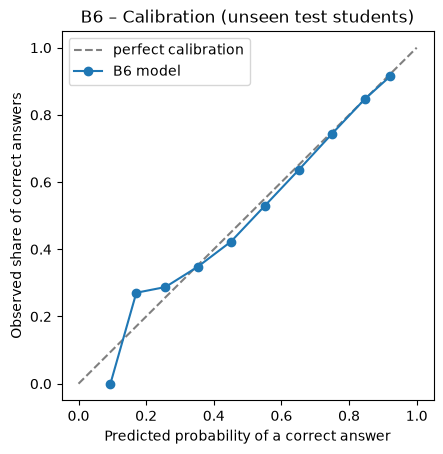

In [59]:
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve

p_test = b6_model.predict_proba(b6_test[B6_FEATURES])[:, 1]
print(f"Accuracy (threshold 0.5): {accuracy_score(b6_test['is_correct'], p_test >= 0.5):.3f}")
print(f"ROC AUC:                  {roc_auc_score(b6_test['is_correct'], p_test):.3f}")
print(f"Share of correct answers in the test set (always guessing 'correct'): {b6_test['is_correct'].mean():.3f}")

observed, predicted = calibration_curve(b6_test["is_correct"], p_test, n_bins=10)
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="perfect calibration")
ax.plot(predicted, observed, marker="o", label="B6 model")
ax.set_xlabel("Predicted probability of a correct answer")
ax.set_ylabel("Observed share of correct answers")
ax.set_title("B6 – Calibration (unseen test students)")
ax.legend()
save_figure(fig, "b6_calibration.png")
plt.show()

Coefficients (positive -> more likely correct):
difficulty             -0.379
topic_fractions        -0.259
attention_distracted   -0.229
topic_division         -0.133
attention_tired        -0.082
prev_hesitant_ratio    -0.059
topic_multiplication   -0.042
recent_correct_ratio    0.053
topic_subtraction       0.259
attempt_no              0.319
topic_addition          0.386
prev_correct_ratio      0.424
attention_attentive     0.523


Figure saved: outputs/b6_coefficients.png


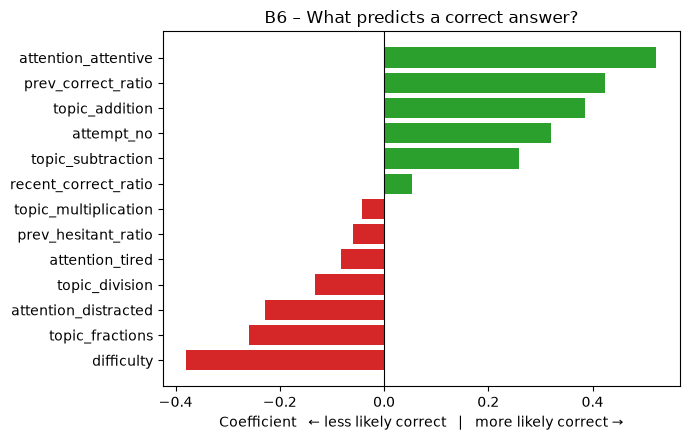

In [60]:
feature_names = b6_model.named_steps["prepare"].get_feature_names_out()
b6_coefficients = pd.Series(b6_model.named_steps["classifier"].coef_[0],
                            index=[n.split("__")[1] for n in feature_names]).sort_values()
print("Coefficients (positive -> more likely correct):")
print(b6_coefficients.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(b6_coefficients.index, b6_coefficients.values,
        color=["tab:red" if c < 0 else "tab:green" for c in b6_coefficients.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient   ← less likely correct   |   more likely correct →")
ax.set_title("B6 – What predicts a correct answer?")
plt.tight_layout()
save_figure(fig, "b6_coefficients.png")
plt.show()

### B6.6 Mastery estimate vs. the truth – and vs. a simple formula

The mastery estimate of a student at any moment = the model's P(correct) for a **medium question while attentive**,
given the student's history. We compare it with the hidden `true_mastery` of the simulation on the unseen test students,
and with a **simple formula without machine learning**: *mastery = correct answers ÷ answers so far* (smoothed).

In [61]:
def mastery_estimate(rows):
    # P(correct) for a medium question while attentive, using each row's history features
    standard = rows[B6_FEATURES].copy()
    standard["difficulty"] = 2
    standard["attention"] = "attentive"
    return b6_model.predict_proba(standard)[:, 1]


b6_test = b6_test.assign(model_mastery=mastery_estimate(b6_test),
                         formula_mastery=b6_test["prev_correct_ratio"])
b6_error_model = (b6_test["model_mastery"] - b6_test["true_mastery"]).abs().mean()
b6_error_formula = (b6_test["formula_mastery"] - b6_test["true_mastery"]).abs().mean()
print(f"Average error of the mastery estimate (test students):")
print(f"  B6 model:        {b6_error_model * 100:.1f} percentage points")
print(f"  simple formula:  {b6_error_formula * 100:.1f} percentage points")

Average error of the mastery estimate (test students):
  B6 model:        8.1 percentage points
  simple formula:  16.0 percentage points


### B6.7 Cold start – how many placement questions does a new student need?

A new student has no history, so the first estimate is just the average student. The placement test (day 0) gives
the first evidence. Below: the average error of the estimate after the student has answered *k* questions of a topic.

Figure saved: outputs/b6_cold_start.png


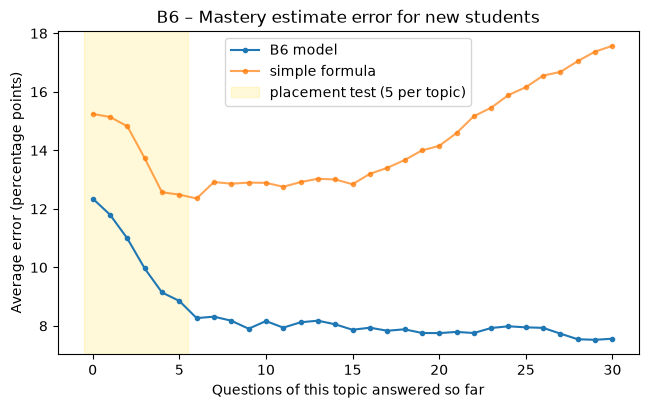

            model  formula
attempt_no                
0            12.4     15.2
1            11.8     15.1
2            11.0     14.8
3            10.0     13.7
5             8.9     12.5
10            8.2     12.9
20            7.8     14.2
30            7.6     17.6


In [62]:
cold = b6_test[b6_test["attempt_no"] <= 30]
cold_error = cold.assign(model=(cold["model_mastery"] - cold["true_mastery"]).abs(),
                         formula=(cold["formula_mastery"] - cold["true_mastery"]).abs()
                         ).groupby("attempt_no")[["model", "formula"]].mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(cold_error.index, cold_error["model"], marker="o", markersize=3, label="B6 model")
ax.plot(cold_error.index, cold_error["formula"], marker="o", markersize=3, label="simple formula", alpha=0.7)
ax.axvspan(-0.5, 5.5, color="gold", alpha=0.15, label="placement test (5 per topic)")
ax.set_xlabel("Questions of this topic answered so far")
ax.set_ylabel("Average error (percentage points)")
ax.set_title("B6 – Mastery estimate error for new students")
ax.legend()
save_figure(fig, "b6_cold_start.png")
plt.show()
print(cold_error.loc[[0, 1, 2, 3, 5, 10, 20, 30]].round(1).to_string())

### B6.8 Block function and Can's mastery over 4 weeks

`b6_mastery(answers)` takes all answers of a student so far and returns the mastery % of every topic.
It adds one "probe" row per topic (a medium question while attentive) after the history and lets the model predict it.

**Can** is simulated as a new student (not in the training data): good at addition, weak at multiplication and fractions.

Before any answer (new student): {'addition': 62.9, 'subtraction': 59.9, 'multiplication': 52.5, 'division': 50.2, 'fractions': 47.1}
After the placement test:        {'addition': 82.8, 'subtraction': 65.5, 'multiplication': 38.8, 'division': 46.1, 'fractions': 44.1}
After 4 weeks:                   {'addition': 86.6, 'subtraction': 86.5, 'multiplication': 53.9, 'division': 67.3, 'fractions': 65.6}


Figure saved: outputs/b6_can_mastery_over_time.png


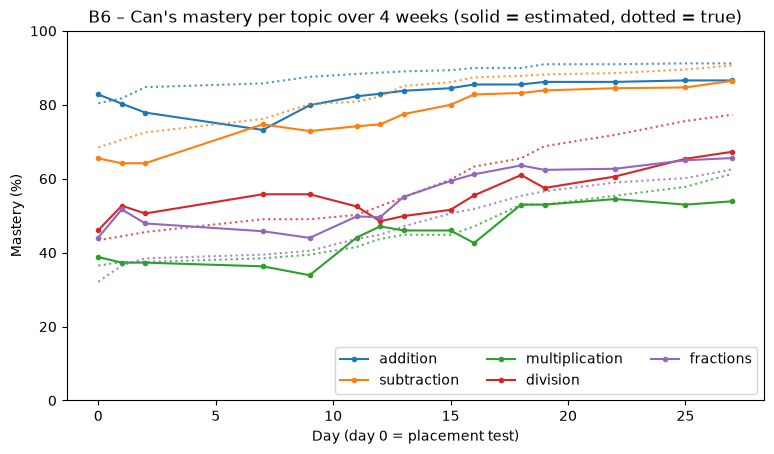

In [63]:
def b6_mastery(answers):
    # Input : all answers of ONE student so far (columns of the simulation log)
    # Output: {topic: mastery in %}
    student = answers["student_id"].iloc[0] if len(answers) else "new"
    next_seq = answers["seq"].max() + 1 if len(answers) else 0
    probes = pd.DataFrame({"student_id": student, "seq": next_seq + np.arange(len(TOPICS)), "topic": TOPICS,
                           "difficulty": 2, "attention": "attentive", "is_correct": np.nan, "is_hesitant": np.nan})
    features = add_history_features(pd.concat([answers, probes], ignore_index=True))
    features = features[features["is_correct"].isna()]
    p = b6_model.predict_proba(features[B6_FEATURES])[:, 1]
    return {topic: round(float(prob) * 100, 1) for topic, prob in zip(features["topic"], p)}


# Can: a new simulated student
can_profile = {"start_skill": {"addition": 1.2, "subtraction": 0.4, "multiplication": -1.3,
                               "division": -0.9, "fractions": -1.6},
               "learning_rate": 0.06, "distractibility": 0.30, "speech_preference": 0.5}
can_log = pd.DataFrame(simulate_student("CAN", can_profile, np.random.default_rng(7)))

print("Before any answer (new student):", b6_mastery(can_log.iloc[0:0]))
print("After the placement test:       ", b6_mastery(can_log[can_log["day"] == 0]))
print("After 4 weeks:                  ", b6_mastery(can_log))

# Time series: mastery at the end of every day, estimated vs. true
days = sorted(can_log["day"].unique())
estimated = pd.DataFrame([b6_mastery(can_log[can_log["day"] <= d]) for d in days], index=days)
true_curve = pd.DataFrame([{t: true_mastery_from_skill(
    can_profile["start_skill"][t] + can_profile["learning_rate"] *
    ((can_log["day"] <= d) & (can_log["topic"] == t)).sum()) * 100 for t in TOPICS} for d in days], index=days)

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, topic in enumerate(TOPICS):
    color = f"C{i}"
    ax.plot(estimated.index, estimated[topic], marker="o", markersize=3, color=color, label=topic)
    ax.plot(true_curve.index, true_curve[topic], linestyle=":", color=color, alpha=0.8)
ax.set_xlabel("Day (day 0 = placement test)")
ax.set_ylabel("Mastery (%)")
ax.set_ylim(0, 100)
ax.set_title("B6 – Can's mastery per topic over 4 weeks (solid = estimated, dotted = true)")
ax.legend(loc="lower right", ncol=3)
save_figure(fig, "b6_can_mastery_over_time.png")
plt.show()

---
## Block B7 – Error Type Discovery (Unsupervised · Combined)

**Role in the tutor:** B6 tells *how often* Can is wrong; B7 tells *why*. Every wrong answer is grouped with
wrong answers that look alike. On the weekend teacher dashboard the teacher sees e.g. *"most of Can's mistakes
are forgotten carries"* and can practise exactly that.

**Why unsupervised:** nobody labels the reason of a wrong answer. The tablet only knows the question and the
answer that B3 (handwriting) or B5a (speech) read. **K-Means** groups similar wrong answers; afterwards we
look at each group and give it a name.

- **Task:** unsupervised clustering (K-Means)
- **Input structure (one row = one wrong answer):**

| Column | Meaning | Source |
|---|---|---|
| `operation` | addition / subtraction / multiplication / division / fractions | question (B6 log) |
| `correct_answer` | the right result (a fraction as its decimal value) | question |
| `given_answer` | the child's answer | **B3** (handwriting) or **B5a** (speech) |
| `difference` | `given_answer − correct_answer` | computed |
| `ratio` | `given_answer ÷ correct_answer` | computed |
| `needs_carry` | 1 if the written method needs a carry (addition, multiplication) or a borrow (subtraction) | question |

- **Output structure:** `cluster_id` → error type **forgot_carry / careless_slip / wrong_operation /
  fraction_rule** + a hint for the teacher. Per student, the shares of the error types and the **characteristic error**
  (the type he makes more often than the average student) → input of **B8**.
- **Data:** synthetic (built on B6's simulated answers). A real dataset for this block is the
  *Eedi NeurIPS 2020 Education Challenge*: millions of answers to diagnostic math questions whose wrong options
  were designed for typical misconceptions.

### B7.1 Data – a question and a wrong answer for every wrong answer of B6

B6's simulation only stored *whether* an answer was correct. For every **wrong** answer of B6 we now create
the question (bigger numbers for harder questions) and the answer the child gave. The answer is produced by
one of four **hidden error types**:

| Hidden error type | Example | What happens |
|---|---|---|
| `forgot_carry` | 47 + 38 → **75** (correct 85) | forgets the carry / borrow → off by exactly 10, 100, … |
| `careless_slip` | 47 + 38 → **84** | off by 1 or 2 (a fraction: numerator off by 1) |
| `wrong_operation` | 47 + 38 → **9** | does another operation (subtracts instead of adding, adds instead of multiplying, …) |
| `fraction_rule` | 1/2 + 1/3 → **2/5** (correct 5/6) | adds the tops and the bottoms separately |

Rules that make the data realistic:
- `forgot_carry` is only possible when the question needs a carry (`needs_carry = 1`). A carry in the **leftmost**
  column does not count: 90 + 20 is written as 110 even without carrying, and 7 + 8 = 15 is a known fact, not a carry.
  The leftmost column is always written in full (85 + 47 → **122**, correct 132).
- Careless slips are **2× more frequent** when B4 says the child is distracted or tired.
- Every student has a **personal tendency** (some forget carries, some mix up operations). B8 will use this.
- Fraction mistakes: 65 % `fraction_rule`, 35 % `careless_slip`. A fraction answer is entered as numerator and
  denominator and kept as written (4/6 is not reduced to 2/3).

The hidden `true_error_type` is **never given to K-Means**. We keep it only to check the clusters in B7.5,
something that is impossible with real data.

In [64]:
from math import lcm

ERROR_TYPES = ["forgot_carry", "careless_slip", "wrong_operation", "fraction_rule"]
SYMBOL = {"addition": "+", "subtraction": "-", "multiplication": "×", "division": "÷", "fractions": "+"}


def make_question(operation, difficulty, rng):
    # Two operands; harder questions use bigger numbers. A fraction is a (numerator, denominator) pair.
    r = lambda lo, hi: int(rng.integers(lo, hi + 1))
    i = difficulty - 1
    if operation == "addition":
        return [(r(2, 9), r(2, 9)), (r(10, 99), r(10, 99)), (r(100, 999), r(10, 999))][i]
    if operation == "subtraction":
        a = [r(5, 18), r(20, 99), r(100, 999)][i]
        return a, (r(2, min(9, a - 1)) if difficulty == 1 else r(10, a - 1))
    if operation == "multiplication":
        return [(r(2, 5), r(2, 5)), (r(2, 9), r(2, 9)), (r(11, 99), r(2, 9))][i]
    if operation == "division":                              # always divides evenly
        b = r(2, 5) if difficulty == 1 else r(2, 9)
        return b * [r(2, 5), r(2, 9), r(11, 30)][i], b
    d1 = [r(3, 8), r(2, 6), r(3, 12)][i]                     # fractions: same denominator when easy
    d2 = d1 if difficulty == 1 else [0, r(2, 6), r(3, 12)][i]
    return (r(1, d1 - 1), d1), (r(1, d2 - 1), d2)


def correct_answer(operation, a, b):
    # Whole numbers -> int; fractions -> (numerator, denominator) over the common denominator
    if operation == "fractions":
        d = lcm(a[1], b[1])
        return (a[0] * d // a[1] + b[0] * d // b[1], d)
    return {"addition": a + b, "subtraction": a - b, "multiplication": a * b, "division": a // b}[operation]


def digit_columns(a, b):
    # The columns of the written method, ones first: 47, 38 -> [(7, 8), (4, 3)]
    n = max(len(str(a)), len(str(b)))
    return [(a // 10**i % 10, b // 10**i % 10) for i in range(n)]


def needs_carry(operation, a, b):
    if operation == "addition":                             # the leftmost column is written in full (9 + 2 = 11),
        return int(any(x + y >= 10 for x, y in digit_columns(a, b)[:-1]))  # so only the other columns carry
    if operation == "subtraction":
        return int(any(x < y for x, y in digit_columns(a, b)))
    if operation == "multiplication":                       # 23 × 4: does the ones column carry?
        return int(a >= 10 and (a % 10) * b >= 10)
    return 0                                                # division, fractions


def wrong_answer(operation, a, b, error_type, rng):
    correct = correct_answer(operation, a, b)
    if error_type == "forgot_carry":
        columns = digit_columns(a, b)
        if operation == "addition":          # 47 + 38 -> 75, 85 + 47 -> 122: writes only the last digit of
            *rest, (x, y) = columns          # every column except the leftmost one, which is written in full
            return sum((p + q) % 10 * 10**i for i, (p, q) in enumerate(rest)) + (x + y) * 10**len(rest)
        if operation == "subtraction":       # 52 - 38 -> 24: borrows but does not take 1 from the next column
            return sum((x - y) % 10 * 10**i for i, (x, y) in enumerate(columns))
        return a // 10 * b * 10 + a % 10 * b % 10      # 23 × 4 -> 82: forgets the carried 1
    if error_type == "careless_slip":
        if operation == "fractions":
            return (correct[0] + int(rng.choice([-1, 1])), correct[1])
        return correct + int(rng.choice([-2, -1, 1, 2]))
    if error_type == "wrong_operation":
        return {"addition": abs(a - b), "subtraction": a + b, "multiplication": a + b, "division": a - b}[operation]
    return (a[0] + b[0], a[1] + b[1])        # fraction_rule: 1/2 + 1/3 -> 2/5


def value(x):                                # 5 -> 5.0, (5, 6) -> 0.833...
    return x[0] / x[1] if isinstance(x, tuple) else float(x)


def as_text(x):                              # 5 -> "5", (5, 6) -> "5/6"
    return f"{x[0]}/{x[1]}" if isinstance(x, tuple) else str(x)


def error_type_weights(operation, has_carry, attention, tendency):
    if operation == "fractions":
        w = np.array([0, 0.35, 0, 0.65])
    else:
        w = np.array([tendency[0] * 2.5 * has_carry, tendency[1], tendency[2], 0])
    if attention != "attentive":
        w[1] *= 2                            # careless slips are more frequent when distracted / tired (B4)
    return w / w.sum()


def add_wrong_answers(log, tendency, rng):
    # For every wrong answer of a B6 log: create the question, pick a hidden error type, produce the given answer
    rows = []
    for ans in log[log["is_correct"] == 0].itertuples():
        while True:
            a, b = make_question(ans.topic, ans.difficulty, rng)
            correct = correct_answer(ans.topic, a, b)
            has_carry = needs_carry(ans.topic, a, b)
            p = error_type_weights(ans.topic, has_carry, ans.attention, tendency[ans.student_id])
            error_type = str(rng.choice(ERROR_TYPES, p=p))
            given = wrong_answer(ans.topic, a, b, error_type, rng)
            if given != correct and value(given) > 0:
                break                        # otherwise (e.g. 2 + 2 = 2 × 2) draw a new question
        rows.append({"student_id": ans.student_id, "day": ans.day, "attention": ans.attention,
                     "operation": ans.topic, "difficulty": ans.difficulty,
                     "question": f"{as_text(a)} {SYMBOL[ans.topic]} {as_text(b)}",
                     "correct_text": as_text(correct), "given_text": as_text(given),
                     "correct_answer": value(correct), "given_answer": value(given),
                     "correct_denominator": correct[1] if isinstance(correct, tuple) else 1,
                     "given_denominator": given[1] if isinstance(given, tuple) else 1,
                     "needs_carry": has_carry, "true_error_type": error_type})
    errors = pd.DataFrame(rows)
    errors["difference"] = errors["given_answer"] - errors["correct_answer"]
    errors["ratio"] = errors["given_answer"] / errors["correct_answer"]
    return errors


b7_rng = np.random.default_rng(RANDOM_STATE + 7)
# Personal tendency of every student for forgot_carry / careless_slip / wrong_operation (shares sum to 1)
b7_tendency = {sid: b7_rng.dirichlet([2, 2, 2]) for sid in b6_profiles}
b7_errors = add_wrong_answers(b6_log, b7_tendency, b7_rng)

B7_COLUMNS = ["operation", "correct_answer", "given_answer", "difference", "ratio", "needs_carry"]
print("Wrong answers:", len(b7_errors), "from", b7_errors["student_id"].nunique(), "students")
print("\nHidden error types (not shown to K-Means):")
print(b7_errors["true_error_type"].value_counts().to_string())
print("\nOne example of every hidden error type:")
examples = b7_errors[b7_errors["difficulty"] == 2].groupby("true_error_type").head(1)
print(examples[["question", "correct_text", "given_text", "true_error_type"]].to_string(index=False))
print("\nThe dataset fed to B7 (first rows):")
b7_errors[B7_COLUMNS].head().round(3)

Wrong answers: 18740 from 200 students

Hidden error types (not shown to K-Means):
true_error_type
careless_slip      9009
wrong_operation    5110
fraction_rule      2934
forgot_carry       1687

One example of every hidden error type:
 question correct_text given_text true_error_type
  20 + 90          110        112   careless_slip
2/6 + 2/3          6/6        4/9   fraction_rule
    6 × 4           24         10 wrong_operation
  44 - 35            9         19    forgot_carry

The dataset fed to B7 (first rows):


,operation,correct_answer,given_answer,difference,ratio,needs_carry
0,addition,110.0,112.000,2.000,1.018,0
1,fractions,0.7,0.600,-0.100,0.857,0
2,fractions,1.0,0.444,-0.556,0.444,0
3,fractions,1.3,0.636,-0.664,0.490,0
4,multiplication,24.0,10.000,-14.000,0.417,0


### B7.2 Preprocessing – describing the *shape* of a mistake

K-Means measures **straight-line distance** between rows, so the columns decide what "similar" means.
The raw columns are a bad fit:
- 47 + 38 → 75 and 472 + 38 → 400 are the same mistake (a forgotten carry), but their `difference` is −10 and −110.
- A careless slip on 9 × 8 (72 → 71) and on 1/4 + 1/4 (2/4 → 1/4) look very different in `difference` and `ratio`.

So we derive **four features that describe the shape of the mistake, independent of the size of the numbers**:

| Feature | Formula | Typical values |
|---|---|---|
| `size_ratio_log` | \|log₂(given ÷ correct)\| | 0 = about the same size, 1 = half or double |
| `error_steps_log` | log₁₀ of \|difference\| counted in steps (a step is 1, or 1/denominator for a fraction) | 0 = one step off, 1 = 10 steps, 2 = 100 steps |
| `diff_is_tens` | 1 if the difference is ±10, ±20, ±100, … | typical of a forgotten carry / borrow |
| `same_denominator` | 1 if a fraction answer keeps the correct denominator (always 1 for whole numbers) | 0 typical of fraction_rule |

`operation` and `needs_carry` describe the **question**, not the mistake, so they are not used for clustering
(B7.5 shows what happens when the raw columns are used). Then the rule from the earlier blocks:
**always scale before K-Means**, otherwise the feature with the largest numbers dominates the distance.

There is **no train/test split**: there are no labels to test against. In the app the scaler and K-Means are
fitted on the stored wrong answers once, and every new wrong answer is only `transform`ed and assigned.

In [65]:
B7_FEATURES = ["size_ratio_log", "error_steps_log", "diff_is_tens", "same_denominator"]


def b7_features(df):
    # Turn (correct answer, given answer) into four numbers that describe the shape of the mistake
    steps = df["difference"].abs() * df["correct_denominator"]          # 1/6 off over sixths = 1 step
    return pd.DataFrame({
        "size_ratio_log": np.log2(df["ratio"].clip(lower=1 / 64)).abs(),
        "error_steps_log": np.log10(steps),
        "diff_is_tens": ((df["operation"] != "fractions") & (df["difference"] % 10 == 0)).astype(int),
        "same_denominator": (df["given_denominator"] == df["correct_denominator"]).astype(int),
    }, index=df.index)


b7_X = b7_features(b7_errors)
b7_scaler = StandardScaler()
b7_X_scaled = b7_scaler.fit_transform(b7_X)

shown = b7_errors[["question", "correct_text", "given_text"]].join(b7_X.round(2))
print(shown.loc[examples.index].to_string(index=False))
print("\nAfter scaling every feature has mean 0 and standard deviation 1:")
print(pd.DataFrame(b7_X_scaled, columns=B7_FEATURES).describe().loc[["mean", "std"]].round(2).to_string())

 question correct_text given_text  size_ratio_log  error_steps_log  diff_is_tens  same_denominator
  20 + 90          110        112            0.03             0.30             0                 1
2/6 + 2/3          6/6        4/9            1.17             0.52             0                 0
    6 × 4           24         10            1.26             1.15             0                 1
  44 - 35            9         19            1.08             1.00             1                 1

After scaling every feature has mean 0 and standard deviation 1:
      size_ratio_log  error_steps_log  diff_is_tens  same_denominator
mean             0.0             -0.0           0.0              -0.0
std              1.0              1.0           1.0               1.0


### B7.3 How many clusters? – Elbow and silhouette

K-Means needs the number of clusters *k* in advance. We try k = 2 … 8 and look at two measures:
- **Inertia (elbow method):** the total distance of the points to their cluster centers. It always drops when
  *k* grows; we look for the "elbow" after which it drops only a little.
- **Silhouette score (−1 … 1):** how much closer every point is to its own cluster than to the nearest other
  cluster. Higher is better.

Figure saved: outputs/b7_choose_k.png


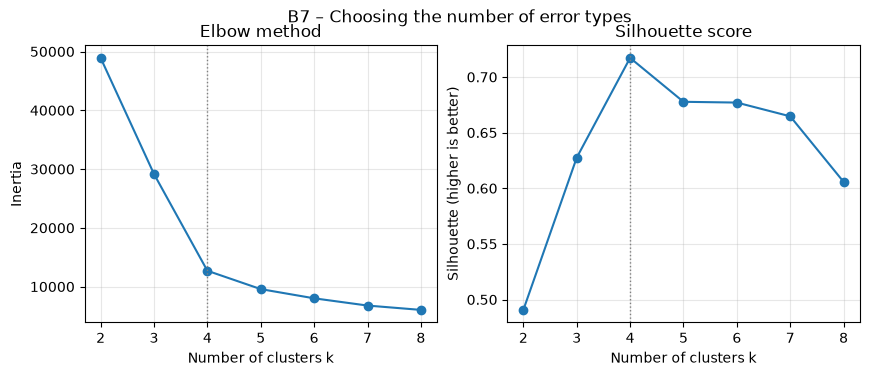

 k  inertia  silhouette
 2  48916.0       0.491
 3  29156.0       0.628
 4  12696.0       0.717
 5   9575.0       0.678
 6   8010.0       0.677
 7   6777.0       0.665
 8   6039.0       0.606


In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(b7_X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(b7_X_scaled, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette (higher is better)")
for ax in axes:
    ax.axvline(4, color="gray", linestyle=":", linewidth=1)
    ax.grid(alpha=0.3)
fig.suptitle("B7 – Choosing the number of error types")
save_figure(fig, "b7_choose_k.png")
plt.show()
print(pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}
                   ).to_string(index=False))

### B7.4 Model – K-Means with k = 4 and naming the clusters

K-Means only returns cluster numbers 0–3; **a human has to say what they mean**. We look at the average features of
every cluster (the cluster centers) and name them with simple rules, which the code applies automatically:
- the cluster with the most `diff_is_tens` → **forgot_carry**
- the cluster with the fewest `same_denominator` → **fraction_rule**
- of the two remaining clusters: the one with the smaller `error_steps_log` → **careless_slip**, the other → **wrong_operation**

In [67]:
b7_kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
b7_errors["cluster_id"] = b7_kmeans.fit_predict(b7_X_scaled)

# Cluster centers back in the original units (easier to read than scaled values)
centers = pd.DataFrame(b7_scaler.inverse_transform(b7_kmeans.cluster_centers_), columns=B7_FEATURES)
names = {}
names[centers["diff_is_tens"].idxmax()] = "forgot_carry"
names[centers.drop(index=list(names))["same_denominator"].idxmin()] = "fraction_rule"
rest = centers.drop(index=list(names))["error_steps_log"].sort_values().index
names[rest[0]], names[rest[1]] = "careless_slip", "wrong_operation"
B7_CLUSTER_NAMES = dict(sorted(names.items()))

B7_HINTS = {
    "forgot_carry": "Practise column addition / subtraction with carrying and borrowing step by step.",
    "careless_slip": "Knows the method – ask him to check his answer; shorter sessions when tired.",
    "wrong_operation": "Mixes up the operations – practise reading the sign and word problems.",
    "fraction_rule": "Adds tops and bottoms – revisit common denominators with pictures (pizza slices).",
}

b7_errors["error_type"] = b7_errors["cluster_id"].map(B7_CLUSTER_NAMES)
summary = centers.round(2).assign(name=pd.Series(B7_CLUSTER_NAMES),
                                  size=b7_errors["cluster_id"].value_counts().sort_index())
summary.index.name = "cluster_id"
print(summary.to_string())

            size_ratio_log  error_steps_log  diff_is_tens  same_denominator             name   size
cluster_id                                                                                         
0                     0.30             0.18          0.00               1.0    careless_slip  10296
1                     1.01             0.70         -0.00               0.0    fraction_rule   2934
2                     0.68             1.40          1.00               1.0     forgot_carry   2110
3                     2.24             1.77          0.01               1.0  wrong_operation   3400


### B7.5 Evaluation – do the clusters match the hidden error types?

With real data we could only judge the clusters by looking at them. Because our data is synthetic, we can
compare the clusters with the hidden `true_error_type`:
- a **cross table** (rows: hidden type, columns: cluster found, values: % of the row),
- the **Adjusted Rand Index (ARI)**: 1 = the clusters match the hidden types perfectly, 0 = no better than random.

For comparison we also run K-Means on the **raw input columns** (`operation` one-hot, `correct_answer`,
`given_answer`, `difference`, `ratio`, `needs_carry`) to see why the feature design of B7.2 matters.

In [68]:
cross = pd.crosstab(b7_errors["true_error_type"], b7_errors["error_type"], normalize="index") * 100
print("Rows: hidden error type, columns: cluster found by K-Means (% of the row)")
print(cross.reindex(index=ERROR_TYPES, columns=ERROR_TYPES).round(1).to_string())

ari = adjusted_rand_score(b7_errors["true_error_type"], b7_errors["cluster_id"])
agreement = (b7_errors["true_error_type"] == b7_errors["error_type"]).mean()
print(f"\nAdjusted Rand Index (shape features): {ari:.3f}")
print(f"Wrong answers whose cluster name equals the hidden type: {agreement:.1%}")

# Comparison: the same K-Means on the raw input columns
raw = ColumnTransformer([("num", StandardScaler(), ["correct_answer", "given_answer", "difference", "ratio"]),
                         ("cat", OneHotEncoder(), ["operation"]),
                         ("bin", "passthrough", ["needs_carry"])]).fit_transform(b7_errors)
raw_labels = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(raw)
print(f"Adjusted Rand Index (raw columns):    {adjusted_rand_score(b7_errors['true_error_type'], raw_labels):.3f}")

print("\nWrong operations that landed in the careless_slip cluster (small numbers):")
mixed = b7_errors[(b7_errors["true_error_type"] == "wrong_operation") & (b7_errors["error_type"] == "careless_slip")]
print(mixed[["question", "correct_text", "given_text"]].head(4).to_string(index=False))

Rows: hidden error type, columns: cluster found by K-Means (% of the row)
error_type       forgot_carry  careless_slip  wrong_operation  fraction_rule
true_error_type                                                             
forgot_carry             99.9            0.0              0.1            0.0
careless_slip             0.0          100.0              0.0            0.0
wrong_operation           8.3           25.2             66.5            0.0
fraction_rule             0.0            0.0              0.0          100.0

Adjusted Rand Index (shape features): 0.768
Wrong answers whose cluster name equals the hidden type: 90.9%
Adjusted Rand Index (raw columns):    0.028

Wrong operations that landed in the careless_slip cluster (small numbers):
question correct_text given_text
   2 × 3            6          5
   7 × 3           21         10
   2 + 4            6          2
   6 × 2           12          8


Figure saved: outputs/b7_clusters.png


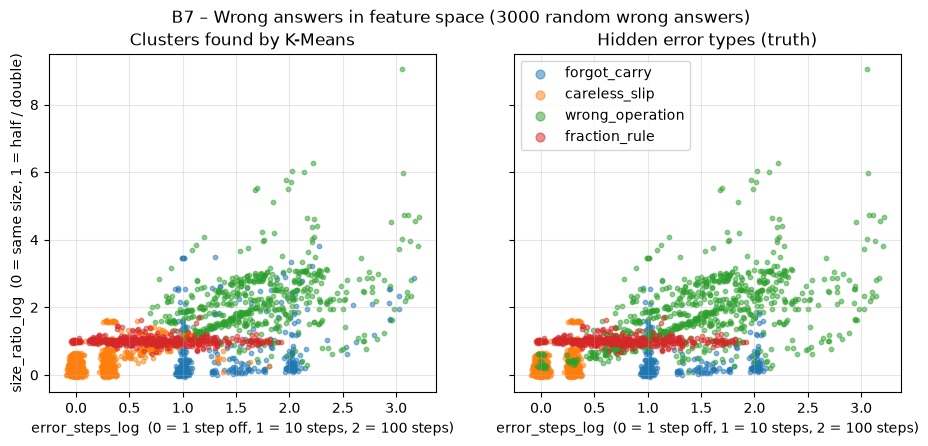

In [69]:
# Scatter plot of the two continuous features: clusters found (left) vs. hidden truth (right)
ERROR_COLORS = {"forgot_carry": "C0", "careless_slip": "C1", "wrong_operation": "C2", "fraction_rule": "C3"}
sample = b7_errors.sample(3000, random_state=RANDOM_STATE)
jitter = np.random.default_rng(RANDOM_STATE).normal(0, 0.03, size=(len(sample), 2))   # avoid hidden overlaps
x = b7_X.loc[sample.index, "error_steps_log"] + jitter[:, 0]
y = b7_X.loc[sample.index, "size_ratio_log"] + jitter[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, column, title in [(axes[0], "error_type", "Clusters found by K-Means"),
                          (axes[1], "true_error_type", "Hidden error types (truth)")]:
    for error_type in ERROR_TYPES:
        mask = (sample[column] == error_type).to_numpy()
        ax.scatter(x[mask], y[mask], s=10, alpha=0.5, color=ERROR_COLORS[error_type], label=error_type)
    ax.set_title(title)
    ax.set_xlabel("error_steps_log  (0 = 1 step off, 1 = 10 steps, 2 = 100 steps)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("size_ratio_log  (0 = same size, 1 = half / double)")
axes[1].legend(loc="upper left", markerscale=2)
fig.suptitle("B7 – Wrong answers in feature space (3000 random wrong answers)")
save_figure(fig, "b7_clusters.png")
plt.show()

### B7.6 Block function and Can's mistakes over 4 weeks

`b7_error_type(operation, a, b, given)` receives one wrong answer (the question and what B3 / B5a read) and
returns the error type and the hint for the teacher. Fractions are written as text, e.g. `"1/2"`.

Then we take **Can's 4 simulated weeks from B6.8**, give him a personal tendency (he often forgets carries),
and let B7 sort all his wrong answers. This is the error part of the teacher dashboard.

**Which error type describes a student?** The simplest choice is the *most common* error type. But careless slips
are frequent for **every** child, so almost everybody would get "careless_slip" and the column would tell B8 nothing.
Instead we use the **characteristic error**: the type a student makes *more often than the average student*
(his share ÷ the average share). This is the input of B8.

In [70]:
def b7_predict(errors):
    # Assign a table of wrong answers (columns as in B7.1) to the four error types
    clusters = b7_kmeans.predict(b7_scaler.transform(b7_features(errors)))
    return pd.Series(clusters, index=errors.index).map(B7_CLUSTER_NAMES)


def b7_error_type(operation, a, b, given):
    # Input : the question (operation, a, b) and the child's answer; fractions as text like "1/2"
    # Output: {error_type, hint}, or None if the answer is correct
    parse = lambda x: tuple(int(p) for p in x.split("/")) if "/" in str(x) else int(x)
    a, b, given = parse(a), parse(b), parse(given)
    correct = correct_answer(operation, a, b)
    if value(given) == value(correct):
        return None
    one = pd.DataFrame([{"operation": operation, "correct_answer": value(correct), "given_answer": value(given),
                         "correct_denominator": correct[1] if isinstance(correct, tuple) else 1,
                         "given_denominator": given[1] if isinstance(given, tuple) else 1}])
    one["difference"] = one["given_answer"] - one["correct_answer"]
    one["ratio"] = one["given_answer"] / one["correct_answer"]
    error_type = b7_predict(one).iloc[0]
    return {"error_type": error_type, "hint": B7_HINTS[error_type]}


print("Can's wrong answers during one session:")
for question in [("addition", 47, 38, 75), ("addition", 47, 38, 84), ("multiplication", 7, 8, 15),
                 ("subtraction", 52, 38, 24), ("fractions", "1/2", "1/3", "2/5"), ("fractions", "1/2", "1/3", "4/6")]:
    operation, a, b, given = question
    result = b7_error_type(*question)
    print(f"  {a} {SYMBOL[operation]} {b} = {given:<4} -> {result['error_type']:<16} {result['hint']}")
print("  47 + 38 = 85   ->", b7_error_type("addition", 47, 38, 85))

Can's wrong answers during one session:
  47 + 38 = 75   -> forgot_carry     Practise column addition / subtraction with carrying and borrowing step by step.
  47 + 38 = 84   -> careless_slip    Knows the method – ask him to check his answer; shorter sessions when tired.
  7 × 8 = 15   -> wrong_operation  Mixes up the operations – practise reading the sign and word problems.
  52 - 38 = 24   -> forgot_carry     Practise column addition / subtraction with carrying and borrowing step by step.
  1/2 + 1/3 = 2/5  -> fraction_rule    Adds tops and bottoms – revisit common denominators with pictures (pizza slices).
  1/2 + 1/3 = 4/6  -> careless_slip    Knows the method – ask him to check his answer; shorter sessions when tired.
  47 + 38 = 85   -> None


Can's wrong answers per week and error type (found by B7):
error_type  forgot_carry  careless_slip  wrong_operation  fraction_rule
week                                                                   
1                      4             12                3              4
2                      5              7                7              2
3                      2              9                2              2
4                      1              8                1              1
Figure saved: outputs/b7_can_errors.png


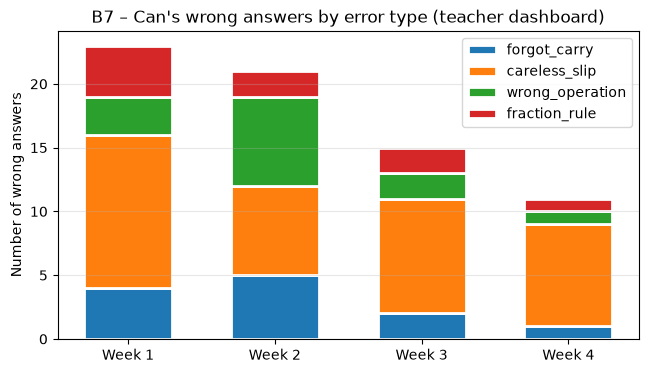


Average share of every error type (all students):
error_type
forgot_carry       0.113
careless_slip      0.547
wrong_operation    0.181
fraction_rule      0.159

Students per most_common_error:      {'careless_slip': 191, 'wrong_operation': 8, 'fraction_rule': 1}
Students per characteristic_error:   {'wrong_operation': 67, 'forgot_carry': 51, 'careless_slip': 44, 'fraction_rule': 38}

Hidden personal tendency (rows) vs. characteristic_error found (columns):


characteristic_error  careless_slip  forgot_carry  fraction_rule  wrong_operation
hidden tendency                                                                  
careless_slip                    39            11             24                8
forgot_carry                      3            35              7               16
wrong_operation                   2             5              7               43

Can's share compared with the average student (>1 = more often than others):
error_type
forgot_carry       1.51
careless_slip      0.94
wrong_operation    1.03
fraction_rule      0.81
Characteristic error of Can (input of B8): forgot_carry


In [71]:
# Can's 4 weeks (can_log from B6.8): he tends to forget carries
can_errors = add_wrong_answers(can_log, {"CAN": np.array([0.8, 0.1, 0.1])}, np.random.default_rng(7))
can_errors["error_type"] = b7_predict(can_errors)
can_errors["week"] = can_errors["day"] // 7 + 1

weekly = pd.crosstab(can_errors["week"], can_errors["error_type"]).reindex(columns=ERROR_TYPES, fill_value=0)
print("Can's wrong answers per week and error type (found by B7):")
print(weekly.to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
bottom = np.zeros(len(weekly))
for error_type in ERROR_TYPES:
    ax.bar(weekly.index, weekly[error_type], bottom=bottom, color=ERROR_COLORS[error_type],
           edgecolor="white", linewidth=2, width=0.6, label=error_type)
    bottom += weekly[error_type].to_numpy()
ax.set_xticks(weekly.index, [f"Week {w}" for w in weekly.index])
ax.set_ylabel("Number of wrong answers")
ax.set_title("B7 – Can's wrong answers by error type (teacher dashboard)")
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
save_figure(fig, "b7_can_errors.png")
plt.show()

# Share of every error type per student -> used by B8
b7_student_errors = pd.crosstab(b7_errors["student_id"], b7_errors["error_type"], normalize="index")[ERROR_TYPES]
average_share = b7_student_errors.mean()
b7_student_errors["most_common_error"] = b7_student_errors[ERROR_TYPES].idxmax(axis=1)
# Characteristic error: the type a student makes MORE OFTEN THAN THE AVERAGE STUDENT (share / average share)
b7_student_errors["characteristic_error"] = (b7_student_errors[ERROR_TYPES] / average_share).idxmax(axis=1)

print("\nAverage share of every error type (all students):")
print(average_share.round(3).to_string())
print("\nStudents per most_common_error:     ", b7_student_errors["most_common_error"].value_counts().to_dict())
print("Students per characteristic_error:  ", b7_student_errors["characteristic_error"].value_counts().to_dict())

hidden = pd.Series({sid: ERROR_TYPES[int(np.argmax(t))] for sid, t in b7_tendency.items()}, name="hidden tendency")
print("\nHidden personal tendency (rows) vs. characteristic_error found (columns):")
print(pd.crosstab(hidden, b7_student_errors["characteristic_error"]).to_string())

can_share = can_errors["error_type"].value_counts(normalize=True).reindex(ERROR_TYPES, fill_value=0)
print("\nCan's share compared with the average student (>1 = more often than others):")
print((can_share / average_share).round(2).to_string())
print("Characteristic error of Can (input of B8):", (can_share / average_share).idxmax())

**Reading the results.**
- Can's tendency to forget carries is strong (80 % of his non-fraction mistakes *would* be forgotten carries), yet B7
  finds it only about 1.5× more often than for the average student. Most of his wrong answers are on questions where
  a carry is **impossible** (fractions, division, one-column questions), and careless slips double when he is
  distracted. B7 can only see a weakness on questions that can reveal it – the tutor should therefore give Can more
  questions **with** carries.
- About 38 students get `fraction_rule` as their characteristic error although nobody was given a "fraction"
  tendency. Their characteristic error means *"many of my mistakes are on fractions"*, i.e. they are weak in
  fractions – useful information for B8. Students whose hidden tendency is `careless_slip` are the hardest to
  recognise: careless slips are common for everybody, so "more often than average" is a weak signal.


---
## Block B8 – Student Profiles (Unsupervised · Combined)

**Role in the tutor:** B6 and B7 describe one student at a time. The teacher of a class of 25 needs a shorter
answer: *"which kinds of learners do I have, and what should I do with each kind?"* B8 groups students with a similar
learning pattern into **profiles** and gives every profile a teaching recommendation
(requirement from the previous assignment: *extract students' learning patterns to develop better teaching mechanisms*).

**Why unsupervised:** nobody labels a child as "type A" or "type B" – the profiles are discovered from the data.

- **Task:** unsupervised clustering (K-Means)
- **Input structure (one row = one student, built from the outputs of the other blocks):**

| Column | Meaning | Source |
|---|---|---|
| `avg_accuracy` | share of correct answers over 4 weeks | B6 log (answers graded with B3 / B5a) |
| `learning_speed` | slope of the student's learning curve: how fast the chance of a correct answer grows with practice | B6 log + B6 history feature `attempt_no` |
| `avg_attention` | share of answers given while *attentive* | **B4** |
| `spoken_answer_ratio` | share of answers given by voice instead of handwriting | answer mode (B5a vs. B3) |
| `characteristic_error` | forgot_carry / careless_slip / wrong_operation / fraction_rule (one-hot) | **B7** (see B7.6) |

- **Output structure:** `profile_id` → profile name (e.g. *"Easily distracted"*) + teaching recommendations,
  plus the hint for the student's characteristic error from B7.
- **Data:** synthetic (the 200 simulated students of B6 and their wrong answers from B7). A real dataset for this block
  is **OULAD** (Open University Learning Analytics Dataset): activity and results of ~32,000 students.

### B8.1 Data – one row per student

For every simulated student we collect four numbers from the B6 log; the characteristic error comes from B7.

**How do we measure `learning_speed`?** Our first idea was *"mastery after 4 weeks minus mastery after the placement
test"* (from B6). It has a problem: a child who starts low has much more room to grow, so weak students looked like fast
learners (correlation with the hidden learning rate only 0.36). Instead we draw every student's **learning curve**:
a small Logistic Regression on the student's own answers, `is_correct ~ attempt_no + topic + difficulty + attention`.
The coefficient of `attempt_no` (per 10 questions of a topic) is the learning speed: how much the log-odds of a correct
answer rise with practice, **with topic, difficulty and attention held fixed**. Positive = improving; 0 = no progress.
(Correlation with the hidden learning rate: 0.74, with the hidden ability: about 0 – it measures speed, not level.)

The simulation also knows every student's **hidden traits** (general ability, learning rate, distractibility,
speech preference). They are **not** given to K-Means; we keep them only to check the profiles in B8.5.

In [72]:
B8_NUMERIC = ["avg_accuracy", "learning_speed", "avg_attention", "spoken_answer_ratio"]
B8_COLUMNS = B8_NUMERIC + ["characteristic_error"]


def learning_speed(log):
    # Slope of the learning curve: coefficient of attempt_no (per 10 questions) in a per-student Logistic Regression
    history = add_history_features(log)
    X = pd.get_dummies(history[["topic", "attention"]]).astype(float)
    X["attempt_per_10"] = history["attempt_no"] / 10
    X["difficulty"] = history["difficulty"]
    model = LogisticRegression(max_iter=1000).fit(X, history["is_correct"].astype(int))
    return float(model.coef_[0][list(X.columns).index("attempt_per_10")])


def b8_student_row(log, characteristic_error):
    # One student's B6 log (+ characteristic error from B7) -> the five B8 input values
    return {"avg_accuracy": log["is_correct"].mean(),
            "learning_speed": learning_speed(log),
            "avg_attention": (log["attention"] == "attentive").mean(),
            "spoken_answer_ratio": (log["answer_mode"] == "speech").mean(),
            "characteristic_error": characteristic_error}


b8_df = pd.DataFrame({sid: b8_student_row(log, b7_student_errors.loc[sid, "characteristic_error"])
                      for sid, log in b6_log.groupby("student_id")}).T
b8_df[B8_NUMERIC] = b8_df[B8_NUMERIC].astype(float)
b8_df.index.name = "student_id"

# Hidden traits of the simulation (never shown to K-Means)
b8_hidden = pd.DataFrame({sid: {"ability": np.mean(list(p["start_skill"].values())),
                                "learning_rate": p["learning_rate"],
                                "distractibility": p["distractibility"],
                                "speech_preference": p["speech_preference"]} for sid, p in b6_profiles.items()}).T

print("Students:", len(b8_df))
print(b8_df[B8_NUMERIC].describe().loc[["mean", "std", "min", "max"]].round(3).to_string())
print("\nThe dataset fed to B8 (first rows):")
b8_df.head().round(3)

Students: 200
      avg_accuracy  learning_speed  avg_attention  spoken_answer_ratio
mean         0.608           0.313          0.678                0.389
std          0.112           0.162          0.144                0.191
min          0.304          -0.101          0.242                0.018
max          0.838           0.673          0.907                0.892

The dataset fed to B8 (first rows):


,avg_accuracy,learning_speed,avg_attention,spoken_answer_ratio,characteristic_error
student_id,,,,,
S000,0.623,0.355,0.667,0.359,forgot_carry
S001,0.468,0.264,0.460,0.448,forgot_carry
S002,0.822,0.115,0.797,0.465,forgot_carry
S003,0.701,0.493,0.852,0.492,fraction_rule
S004,0.401,0.236,0.747,0.184,careless_slip


### B8.2 Preprocessing

- The four numeric columns have different units (shares between 0 and 1, a log-odds slope) →
  **StandardScaler** (always scale before K-Means).
- `characteristic_error` is a category → **one-hot** (four 0/1 columns, not scaled). Two students with different errors
  are already √2 ≈ 1.4 apart in these four columns, as much as a big difference in one numeric column. We give the
  one-hot columns a **weight of 0.5** (`transformer_weights`) so that the error type adds information without
  splitting the class only by error type.

As in B7 there is no train/test split (no labels). A new student is only `transform`ed and assigned to the nearest profile.

In [73]:
b8_prepare = ColumnTransformer([("numeric", StandardScaler(), B8_NUMERIC),
                                ("error", OneHotEncoder(categories=[ERROR_TYPES]), ["characteristic_error"])],
                               transformer_weights={"numeric": 1.0, "error": 0.5})
b8_X = b8_prepare.fit_transform(b8_df)
b8_feature_names = [n.split("__")[1] for n in b8_prepare.get_feature_names_out()]
print("Columns given to K-Means:", b8_feature_names)
print("\nFirst student before and after preprocessing:")
print(pd.DataFrame([b8_X[0]], columns=b8_feature_names, index=[b8_df.index[0]]).round(2).to_string())

Columns given to K-Means: ['avg_accuracy', 'learning_speed', 'avg_attention', 'spoken_answer_ratio', 'characteristic_error_forgot_carry', 'characteristic_error_careless_slip', 'characteristic_error_wrong_operation', 'characteristic_error_fraction_rule']

First student before and after preprocessing:
      avg_accuracy  learning_speed  avg_attention  spoken_answer_ratio  characteristic_error_forgot_carry  characteristic_error_careless_slip  characteristic_error_wrong_operation  characteristic_error_fraction_rule
S000          0.13            0.26          -0.08                -0.16                                0.5                                 0.0                                   0.0                                 0.0


### B8.3 How many profiles? – Elbow and silhouette

Figure saved: outputs/b8_choose_k.png


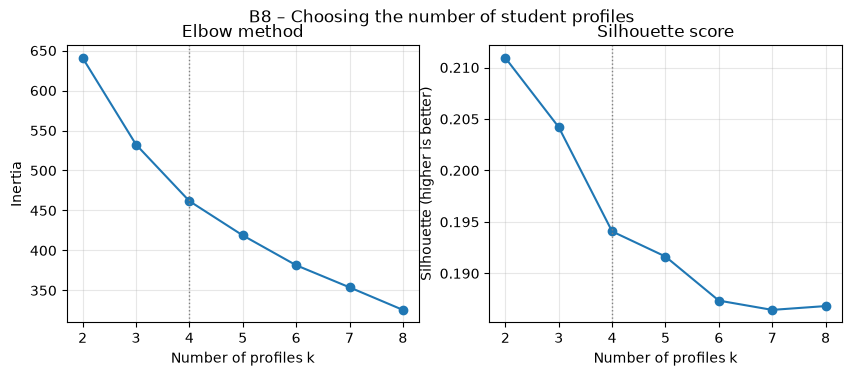

 k  inertia  silhouette
 2    640.9       0.211
 3    532.5       0.204
 4    461.7       0.194
 5    418.8       0.192
 6    381.5       0.187
 7    353.9       0.186
 8    325.6       0.187


In [74]:
k_values = range(2, 9)
b8_inertias, b8_silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(b8_X)
    b8_inertias.append(km.inertia_)
    b8_silhouettes.append(silhouette_score(b8_X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(list(k_values), b8_inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of profiles k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), b8_silhouettes, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of profiles k")
axes[1].set_ylabel("Silhouette (higher is better)")
for ax in axes:
    ax.axvline(4, color="gray", linestyle=":", linewidth=1)
    ax.grid(alpha=0.3)
fig.suptitle("B8 – Choosing the number of student profiles")
save_figure(fig, "b8_choose_k.png")
plt.show()
print(pd.DataFrame({"k": list(k_values), "inertia": np.round(b8_inertias, 1),
                    "silhouette": np.round(b8_silhouettes, 3)}).to_string(index=False))

**Result:** the silhouette stays around 0.2 for every *k* and there is no clear elbow. This is an honest finding:
children are not made of a few separate types – ability, learning speed and attention vary **continuously**
(they did in our simulation, and they do in real classes). K-Means still gives a useful **segmentation**: it cuts
the class into groups of similar students. We choose **k = 4**: a teacher can follow four teaching strategies,
and four groups are still easy to name (B8.4).

### B8.4 Model – K-Means with k = 4 and naming the profiles

Every profile is named after the features where its center differs most from the average student
(center in standard deviations, |z| ≥ 0.5). Each feature direction has a name and a teaching recommendation:

| Feature | high (z ≥ +0.5) | low (z ≤ −0.5) |
|---|---|---|
| `avg_accuracy` | *Strong student* – give challenge problems | *Needs support* – repeat basics, easier questions first |
| `learning_speed` | *Fast learner* – move to the next level sooner | *Slow progress* – more practice per topic, spaced repetition |
| `avg_attention` | *Focused* – longer sessions are fine | *Easily distracted* – short sessions (10 min), breaks, game elements |
| `spoken_answer_ratio` | *Prefers speaking* – voice answers by default, voice calibration (B5a.9) | *Prefers writing* – handwriting by default |

The code applies this table automatically, so the names stay correct if the data changes.

In [75]:
b8_kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
b8_df["profile_id"] = b8_kmeans.fit_predict(b8_X)

PROFILE_TAGS = {   # feature -> (name if high, recommendation if high, name if low, recommendation if low)
    "avg_accuracy": ("Strong student", "Give challenge problems and word problems.",
                     "Needs support", "Repeat the basics; start every topic with easy questions."),
    "learning_speed": ("Fast learner", "Move to the next difficulty level sooner.",
                       "Slow progress", "More practice per topic; repeat old topics (spaced repetition)."),
    "avg_attention": ("Focused", "Longer sessions are fine.",
                      "Easily distracted", "Short sessions (10 min) with breaks and game elements."),
    "spoken_answer_ratio": ("Prefers speaking", "Voice answers by default; run the voice calibration (B5a.9).",
                            "Prefers writing", "Handwriting answers by default."),
}

# Profile centers in standard deviations (z) for the four numeric features
b8_centers_z = pd.DataFrame(b8_kmeans.cluster_centers_[:, :len(B8_NUMERIC)], columns=B8_NUMERIC)


def describe_profile(center_z):
    # Name and recommendations of one profile center: features with |z| >= 0.5, the strongest first
    tags = center_z[center_z.abs() >= 0.5].abs().sort_values(ascending=False).index
    tags = tags if len(tags) else [center_z.abs().idxmax()]
    parts = [PROFILE_TAGS[f][0 if center_z[f] > 0 else 2] for f in tags]
    advice = [PROFILE_TAGS[f][1 if center_z[f] > 0 else 3] for f in tags]
    return " · ".join(parts[:2]), advice


B8_PROFILES = {pid: dict(zip(["name", "recommendations"], describe_profile(b8_centers_z.loc[pid])))
               for pid in b8_centers_z.index}

b8_summary = b8_df.groupby("profile_id")[B8_NUMERIC].mean().round(3)
b8_summary.insert(0, "name", [B8_PROFILES[p]["name"] for p in b8_summary.index])
b8_summary["students"] = b8_df["profile_id"].value_counts().sort_index()
print("Profile centers (original units):")
print(b8_summary.to_string())
print("\nCharacteristic error inside every profile (% of the profile):")
print((pd.crosstab(b8_df["profile_id"], b8_df["characteristic_error"], normalize="index") * 100)
      .reindex(columns=ERROR_TYPES).round(0).to_string())
for pid, profile in B8_PROFILES.items():
    print(f"\nProfile {pid} – {profile['name']}")
    for advice in profile["recommendations"]:
        print("   •", advice)

Profile centers (original units):
                                      name  avg_accuracy  learning_speed  avg_attention  spoken_answer_ratio  students
profile_id                                                                                                            
0           Fast learner · Prefers writing         0.678           0.440          0.753                0.261        62
1                         Prefers speaking         0.640           0.322          0.697                0.577        56
2            Slow progress · Needs support         0.481           0.110          0.754                0.380        38
3                        Easily distracted         0.577           0.298          0.483                0.336        44

Characteristic error inside every profile (% of the profile):
characteristic_error  forgot_carry  careless_slip  wrong_operation  fraction_rule
profile_id                                                                       
0                        

### B8.5 Evaluation – do the profiles mean something?

Without labels there is no accuracy. We check the profiles in three ways:
1. **Center heatmap:** how every profile differs from the average student (in standard deviations).
2. **2-D picture (PCA):** the students projected onto the two directions with the most variation, colored by profile.
3. **Hidden traits of the simulation:** if the profiles are meaningful, e.g. the *"Easily distracted"* profile must
   contain students whose hidden distractibility is high. (Possible only with synthetic data.)

Figure saved: outputs/b8_profiles.png


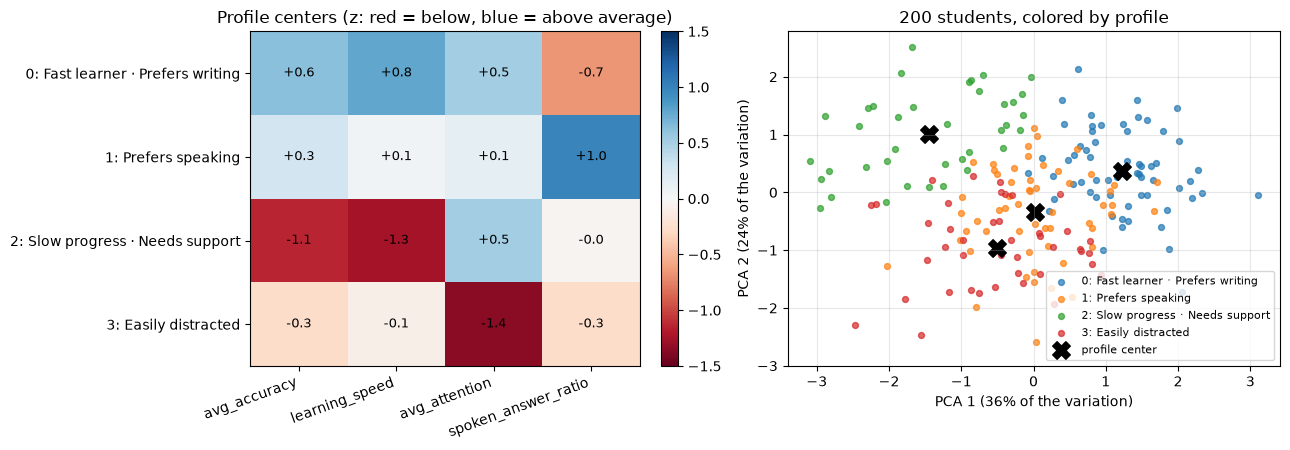

Average HIDDEN traits per profile (never seen by K-Means):
                                   ability  learning_rate  distractibility  speech_preference
profile_id                                                                                   
0: Fast learner · Prefers writing   -0.183          0.061            0.151              0.268
1: Prefers speaking                 -0.205          0.050            0.207              0.580
2: Slow progress · Needs support    -0.706          0.024            0.149              0.375
3: Easily distracted                -0.319          0.050            0.413              0.339

Correlation between the B8 inputs and the hidden traits:
                     ability  learning_rate  distractibility  speech_preference
avg_accuracy            0.75           0.55            -0.16              -0.06
learning_speed          0.00           0.75             0.00              -0.09
avg_attention          -0.02          -0.08            -0.98              -0.06

In [76]:
from sklearn.decomposition import PCA

profile_labels = [f"{p}: {B8_PROFILES[p]['name']}" for p in b8_centers_z.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})
image = axes[0].imshow(b8_centers_z.to_numpy(), cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
axes[0].set_xticks(range(len(B8_NUMERIC)), B8_NUMERIC, rotation=20, ha="right")
axes[0].set_yticks(range(len(profile_labels)), profile_labels)
for (i, j), z in np.ndenumerate(b8_centers_z.to_numpy()):
    axes[0].text(j, i, f"{z:+.1f}", ha="center", va="center", fontsize=9)
axes[0].set_title("Profile centers (z: red = below, blue = above average)")
fig.colorbar(image, ax=axes[0], fraction=0.04)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
points = pca.fit_transform(b8_X)
for pid in b8_centers_z.index:
    mask = (b8_df["profile_id"] == pid).to_numpy()
    axes[1].scatter(points[mask, 0], points[mask, 1], s=18, alpha=0.7, color=f"C{pid}", label=profile_labels[pid])
centers_2d = pca.transform(b8_kmeans.cluster_centers_)
axes[1].scatter(centers_2d[:, 0], centers_2d[:, 1], marker="X", s=160, color="black", label="profile center")
axes[1].set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]:.0%} of the variation)")
axes[1].set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]:.0%} of the variation)")
axes[1].set_title("200 students, colored by profile")
axes[1].legend(fontsize=8, loc="best")
axes[1].grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "b8_profiles.png")
plt.show()

print("Average HIDDEN traits per profile (never seen by K-Means):")
print(b8_hidden.astype(float).join(b8_df["profile_id"]).groupby("profile_id").mean()
      .rename(index=lambda p: profile_labels[p]).round(3).to_string())
print("\nCorrelation between the B8 inputs and the hidden traits:")
print(b8_df[B8_NUMERIC].join(b8_hidden.astype(float)).corr().loc[B8_NUMERIC, b8_hidden.columns].round(2).to_string())

**Reading the check.** `avg_attention` mirrors the hidden distractibility almost perfectly and `spoken_answer_ratio`
the speech preference. `learning_speed` follows the hidden learning rate well but not perfectly: about 250 noisy answers
in four weeks are few for measuring a slope; over a whole semester it would become more reliable. `avg_accuracy` mixes
ability and learning rate (a fast learner also answers more correctly), which is why the profiles *"Strong student"* and
*"Fast learner"* overlap a little.

### B8.6 Block function and Can's profile

`b8_student_profile(...)` receives the five values of one student and returns the profile and the recommendations,
plus the B7 hint for the student's characteristic error. Can is a **new** student (not used to fit K-Means): his
values are built from his 4 simulated weeks (B6.8) and his error types (B7.6), then only transformed and assigned.

In [77]:
def b8_student_profile(avg_accuracy, learning_speed, avg_attention, spoken_answer_ratio, characteristic_error):
    # Input : the five B8 values of one student
    # Output: {profile_id, profile, recommendations, error_hint}
    row = pd.DataFrame([{"avg_accuracy": avg_accuracy, "learning_speed": learning_speed,
                         "avg_attention": avg_attention, "spoken_answer_ratio": spoken_answer_ratio,
                         "characteristic_error": characteristic_error}])
    profile_id = int(b8_kmeans.predict(b8_prepare.transform(row))[0])
    return {"profile_id": profile_id,
            "profile": B8_PROFILES[profile_id]["name"],
            "recommendations": B8_PROFILES[profile_id]["recommendations"],
            "error_hint": B7_HINTS[characteristic_error]}


can_share = can_errors["error_type"].value_counts(normalize=True).reindex(ERROR_TYPES, fill_value=0)
can_row = b8_student_row(can_log, (can_share / average_share).idxmax())
print("Can's B8 input:")
for column, val in can_row.items():
    print(f"   {column:<22} {val if isinstance(val, str) else round(val, 3)}")

can_profile_result = b8_student_profile(**can_row)
print("\nB8 output for Can:")
print("   profile:", can_profile_result["profile_id"], "–", can_profile_result["profile"])
for advice in can_profile_result["recommendations"]:
    print("   •", advice)
print("   • error:", can_profile_result["error_hint"])

print("\nTwo invented students:")
print("  ", b8_student_profile(0.80, 0.9, 0.85, 0.2, "careless_slip")["profile"])
print("  ", b8_student_profile(0.45, 0.1, 0.70, 0.7, "fraction_rule")["profile"])

Can's B8 input:
   avg_accuracy           0.581
   learning_speed         0.326
   avg_attention          0.611
   spoken_answer_ratio    0.527
   characteristic_error   forgot_carry

B8 output for Can:
   profile: 1 – Prefers speaking
   • Voice answers by default; run the voice calibration (B5a.9).
   • error: Practise column addition / subtraction with carrying and borrowing step by step.

Two invented students:
   Fast learner · Prefers writing
   Slow progress · Needs support
